In [1]:
# Step 1: Import libraries for data manipulation
import pandas as pd
import numpy as np

# Step 2: Import libraries for visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Step 3: Configure plots
plt.rcParams["figure.figsize"] = (12, 6)
plt.rcParams["axes.grid"] = True

# Step 4: Confirm successful imports
print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
# Step 1: Load the CSV file into a pandas DataFrame
df = pd.read_csv("CP2_data_ts.csv")

# Step 2: Display the first five observations
print("First five observations:")
display(df.head())

# Step 3: Display the last five observations
print("\nLast five observations:")
display(df.tail())

# Step 4: Check the number of rows and columns
print("\nDataset shape:", df.shape)

# Step 5: Display the column names
print("\nColumn names:")
print(df.columns.tolist())

# Step 6: Inspect the data types and non-null counts
print("\nDataset information:")
df.info()

First five observations:


,Date,"Daily minimum temperatures in Melbourne, Australia, 1981-1990"
0,01-01-1981,20.7
1,02-01-1981,17.9
2,03-01-1981,18.8
3,04-01-1981,14.6
4,05-01-1981,15.8



Last five observations:


,Date,"Daily minimum temperatures in Melbourne, Australia, 1981-1990"
3645,27-12-1990,14
3646,28-12-1990,13.6
3647,29-12-1990,13.5
3648,30-12-1990,15.7
3649,31-12-1990,13



Dataset shape: (3650, 2)

Column names:
['Date', 'Daily minimum temperatures in Melbourne, Australia, 1981-1990']

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 3650 entries, 0 to 3649
Data columns (total 2 columns):
 #   Column                                                         Non-Null Count  Dtype
---  ------                                                         --------------  -----
 0   Date                                                           3650 non-null   str  
 1   Daily minimum temperatures in Melbourne, Australia, 1981-1990  3650 non-null   str  
dtypes: str(2)
memory usage: 104.7 KB


In [3]:
# Step 1: Check missing values in each column
print("Missing values:")
print(df.isnull().sum())

# Step 2: Check duplicate rows
print("\nDuplicate rows:", df.duplicated().sum())

# Step 3: Check duplicate dates
print("Duplicate dates:", df["Date"].duplicated().sum())

# Step 4: Identify invalid temperature values
temperature_column = df.columns[1]

numeric_temperature = pd.to_numeric(
    df[temperature_column],
    errors="coerce"
)

invalid_mask = numeric_temperature.isna()

print("\nInvalid temperature values:", invalid_mask.sum())

# Step 5: Display invalid records
display(df.loc[invalid_mask])

Missing values:
Date                                                             0
Daily minimum temperatures in Melbourne, Australia, 1981-1990    0
dtype: int64

Duplicate rows: 0
Duplicate dates: 0

Invalid temperature values: 3


,Date,"Daily minimum temperatures in Melbourne, Australia, 1981-1990"
565,20-07-1982,?0.2
566,21-07-1982,?0.8
1290,14-07-1984,?0.1


In [4]:
# Step 1: Rename the columns
df.columns = ["date", "temperature_original"]

# Step 2: Convert dates into datetime format
df["date"] = pd.to_datetime(
    df["date"],
    format="%d-%m-%Y"
)

# Step 3: Convert temperatures into numeric values
df["temperature"] = pd.to_numeric(
    df["temperature_original"],
    errors="coerce"
)

# Step 4: Sort observations chronologically
df = df.sort_values("date").reset_index(drop=True)

# Step 5: Set date as the time-series index
df = df.set_index("date")

# Step 6: Interpolate invalid temperatures using time
df["temperature"] = df["temperature"].interpolate(
    method="time"
)

# Step 7: Validate the cleaned dataset
print("Dataset shape:", df.shape)
print("Index type:", type(df.index))
print("Missing temperatures:", df["temperature"].isna().sum())
print("Duplicate dates:", df.index.duplicated().sum())
print("Start date:", df.index.min())
print("End date:", df.index.max())

# Step 8: Inspect the corrected records
display(
    df.loc[
        pd.to_datetime([
            "1982-07-20",
            "1982-07-21",
            "1984-07-14"
        ])
    ]
)

Dataset shape: (3650, 2)
Index type: <class 'pandas.DatetimeIndex'>
Missing temperatures: 0
Duplicate dates: 0
Start date: 1981-01-01 00:00:00
End date: 1990-12-31 00:00:00


,temperature_original,temperature
1982-07-20,?0.2,3.766667
1982-07-21,?0.8,2.333333
1984-07-14,?0.1,0.800000


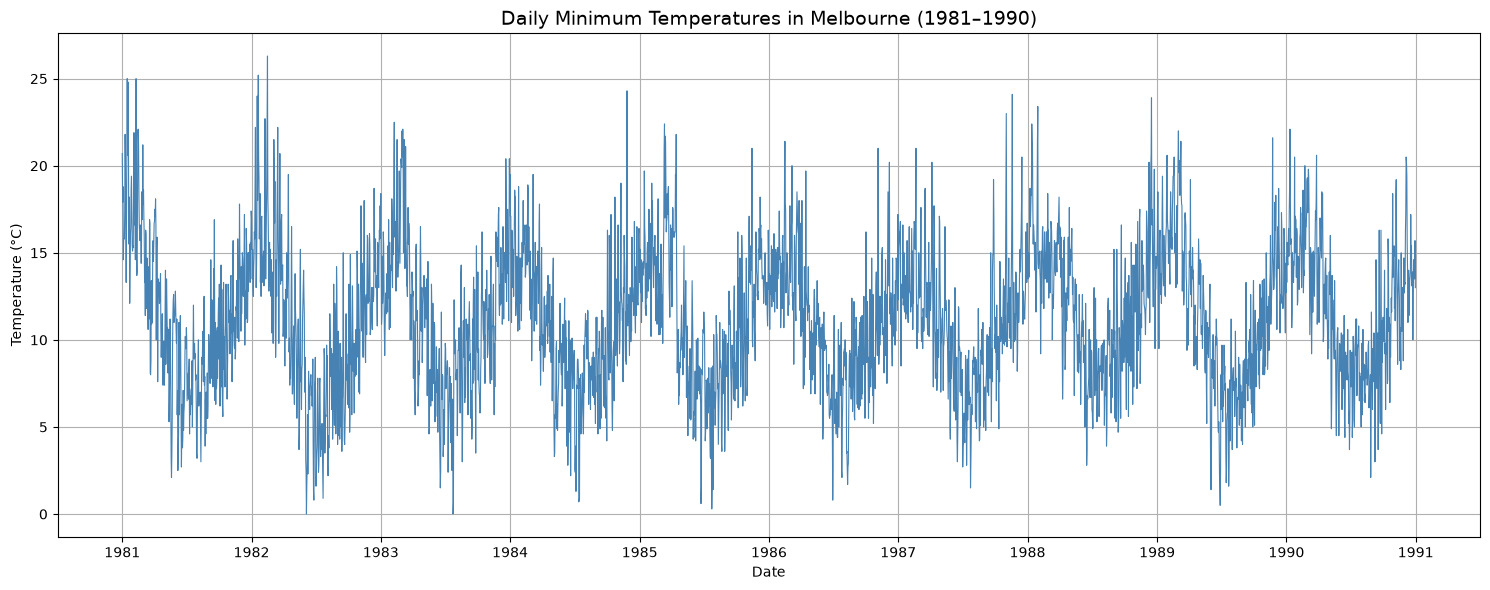

In [5]:
# Step 1: Create the figure
plt.figure(figsize=(15, 6))

# Step 2: Plot daily minimum temperature against date
plt.plot(
    df.index,
    df["temperature"],
    linewidth=0.8,
    color="steelblue"
)

# Step 3: Add chart title and axis labels
plt.title(
    "Daily Minimum Temperatures in Melbourne (1981–1990)",
    fontsize=14
)
plt.xlabel("Date")
plt.ylabel("Temperature (°C)")

# Step 4: Improve layout and display
plt.tight_layout()
plt.show()

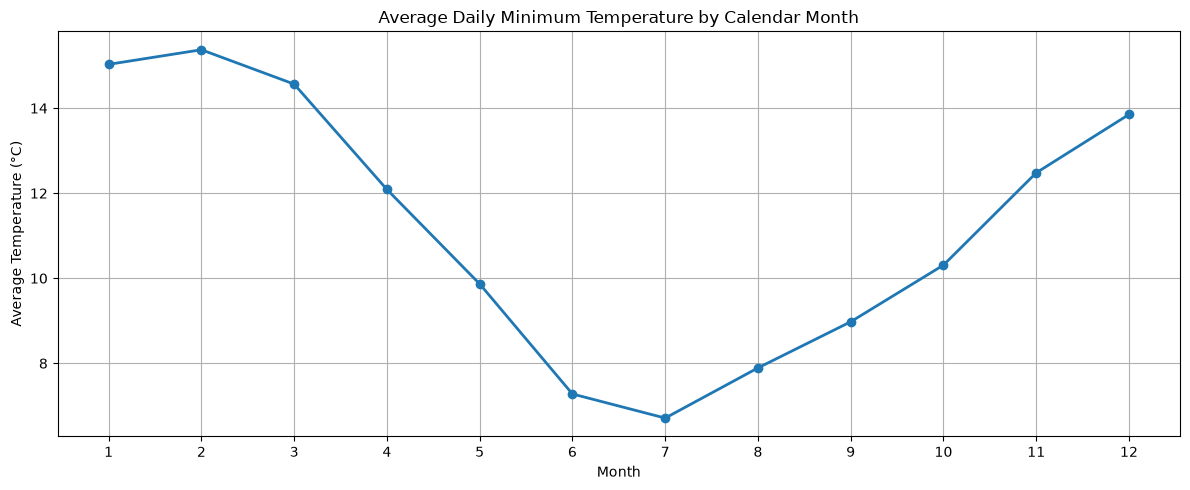

month
1     15.03
2     15.37
3     14.57
4     12.09
5      9.87
6      7.28
7      6.71
8      7.89
9      8.98
10    10.31
11    12.48
12    13.85
Name: temperature, dtype: float64

In [6]:
# Step 1: Extract the month from the datetime index
df["month"] = df.index.month

# Step 2: Calculate average temperature for each month
monthly_avg = df.groupby("month")["temperature"].mean()

# Step 3: Plot monthly average temperature
plt.figure(figsize=(12, 5))

plt.plot(
    monthly_avg.index,
    monthly_avg.values,
    marker="o",
    linewidth=2
)

# Step 4: Label the chart
plt.title("Average Daily Minimum Temperature by Calendar Month")
plt.xlabel("Month")
plt.ylabel("Average Temperature (°C)")
plt.xticks(range(1, 13))
plt.tight_layout()
plt.show()

# Step 5: Display the monthly averages numerically
display(monthly_avg.round(2))

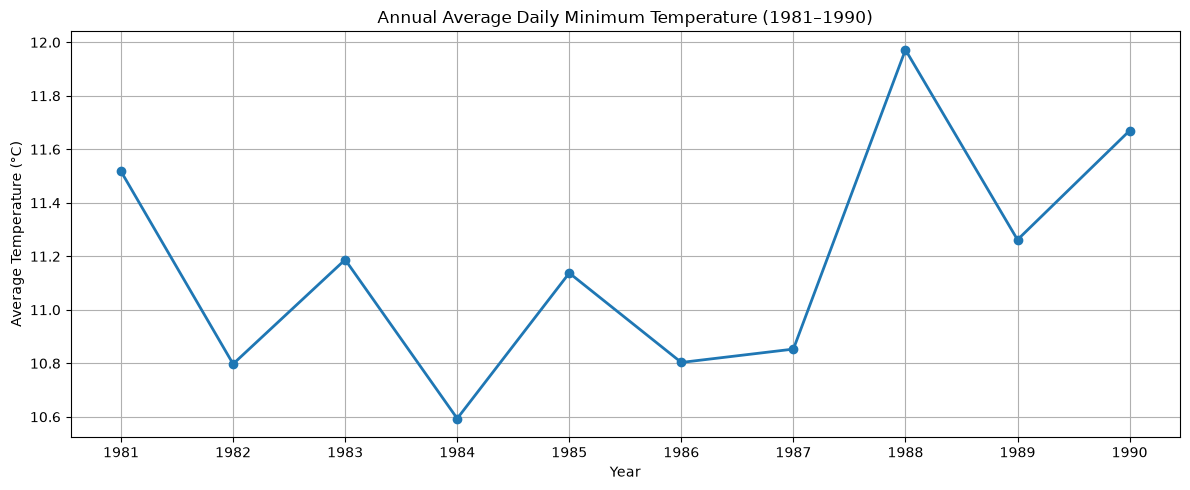

date
1981    11.52
1982    10.80
1983    11.19
1984    10.59
1985    11.14
1986    10.80
1987    10.85
1988    11.97
1989    11.26
1990    11.67
Name: temperature, dtype: float64

In [7]:
# Step 1: Calculate the average temperature for each year
yearly_avg = df["temperature"].resample("YE").mean()

# Step 2: Convert the datetime index into year labels
yearly_avg.index = yearly_avg.index.year

# Step 3: Plot yearly averages
plt.figure(figsize=(12, 5))

plt.plot(
    yearly_avg.index,
    yearly_avg.values,
    marker="o",
    linewidth=2
)

plt.title("Annual Average Daily Minimum Temperature (1981–1990)")
plt.xlabel("Year")
plt.ylabel("Average Temperature (°C)")
plt.xticks(yearly_avg.index)
plt.tight_layout()
plt.show()

# Step 4: Display yearly averages numerically
display(yearly_avg.round(2))

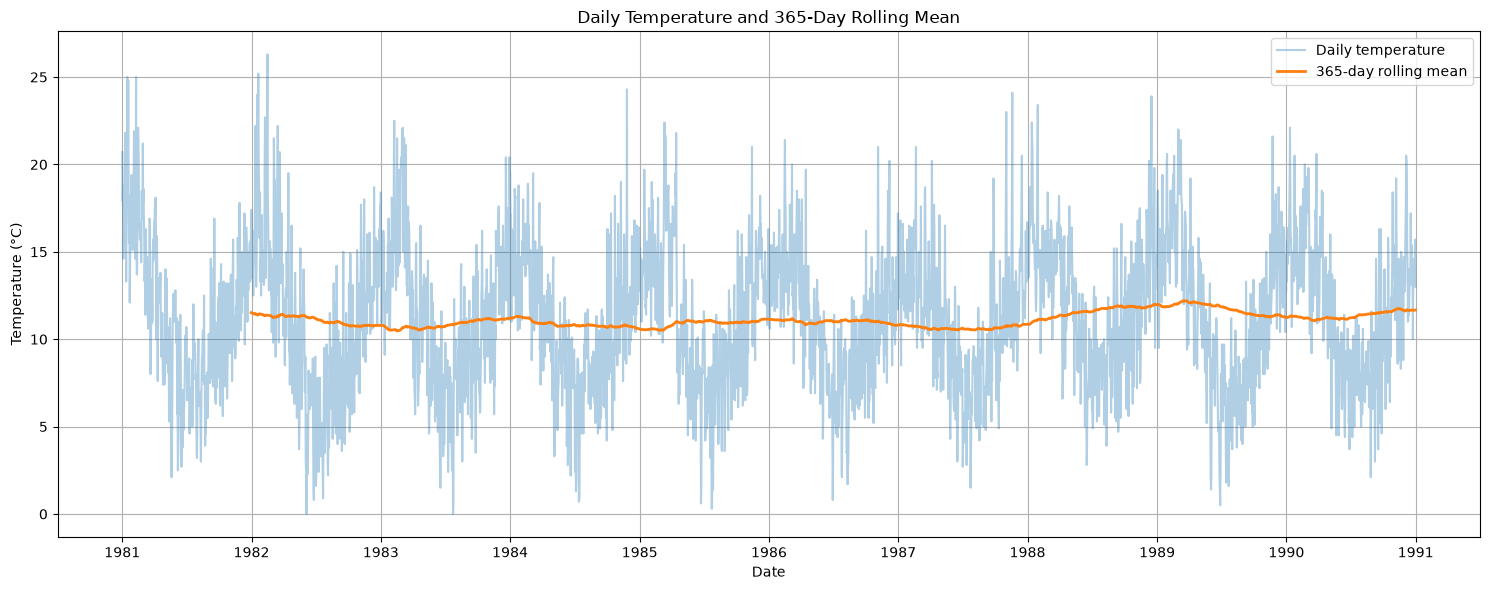

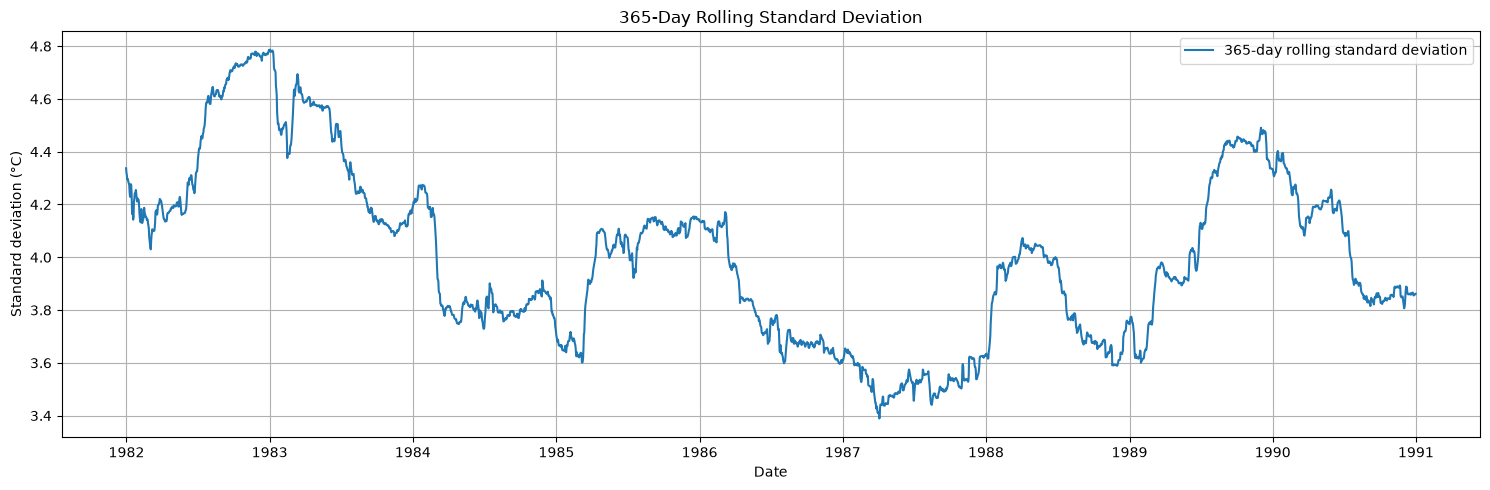

In [8]:
# Step 1: Calculate the rolling mean over 365 days
rolling_mean = df["temperature"].rolling(window=365).mean()

# Step 2: Calculate the rolling standard deviation over 365 days
rolling_std = df["temperature"].rolling(window=365).std()

# Step 3: Plot the original series and rolling mean
plt.figure(figsize=(15, 6))

plt.plot(
    df.index,
    df["temperature"],
    label="Daily temperature",
    alpha=0.35
)

plt.plot(
    df.index,
    rolling_mean,
    label="365-day rolling mean",
    linewidth=2
)

plt.title("Daily Temperature and 365-Day Rolling Mean")
plt.xlabel("Date")
plt.ylabel("Temperature (°C)")
plt.legend()
plt.tight_layout()
plt.show()

# Step 4: Plot the rolling standard deviation
plt.figure(figsize=(15, 5))

plt.plot(
    df.index,
    rolling_std,
    label="365-day rolling standard deviation"
)

plt.title("365-Day Rolling Standard Deviation")
plt.xlabel("Date")
plt.ylabel("Standard deviation (°C)")
plt.legend()
plt.tight_layout()
plt.show()

In [9]:
# Import the Augmented Dickey-Fuller test
from statsmodels.tsa.stattools import adfuller

# Run the ADF test on the original temperature series
adf_result = adfuller(
    df["temperature"],
    autolag="AIC"
)

# Extract the test results
adf_statistic = adf_result[0]
p_value = adf_result[1]
used_lags = adf_result[2]
number_of_observations = adf_result[3]
critical_values = adf_result[4]

# Display the results
print("ADF Statistic:", adf_statistic)
print("p-value:", p_value)
print("Number of lags used:", used_lags)
print("Number of observations:", number_of_observations)

print("\nCritical values:")
for key, value in critical_values.items():
    print(f"{key}: {value}")

# Interpret the p-value at a 5% significance level
if p_value < 0.05:
    print("\nDecision: Reject the null hypothesis.")
    print("The test provides evidence against a unit root.")
else:
    print("\nDecision: Fail to reject the null hypothesis.")
    print("The test does not provide sufficient evidence against a unit root.")

ADF Statistic: -4.44052200655791
p-value: 0.00025147236020337904
Number of lags used: 20
Number of observations: 3629

Critical values:
1%: -3.4321532327220154
5%: -2.862336767636517
10%: -2.56719413172842

Decision: Reject the null hypothesis.
The test provides evidence against a unit root.


C:\Users\hp\AppData\Local\Temp\ipykernel_22264\3839077825.py:5: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf_result = adfuller(


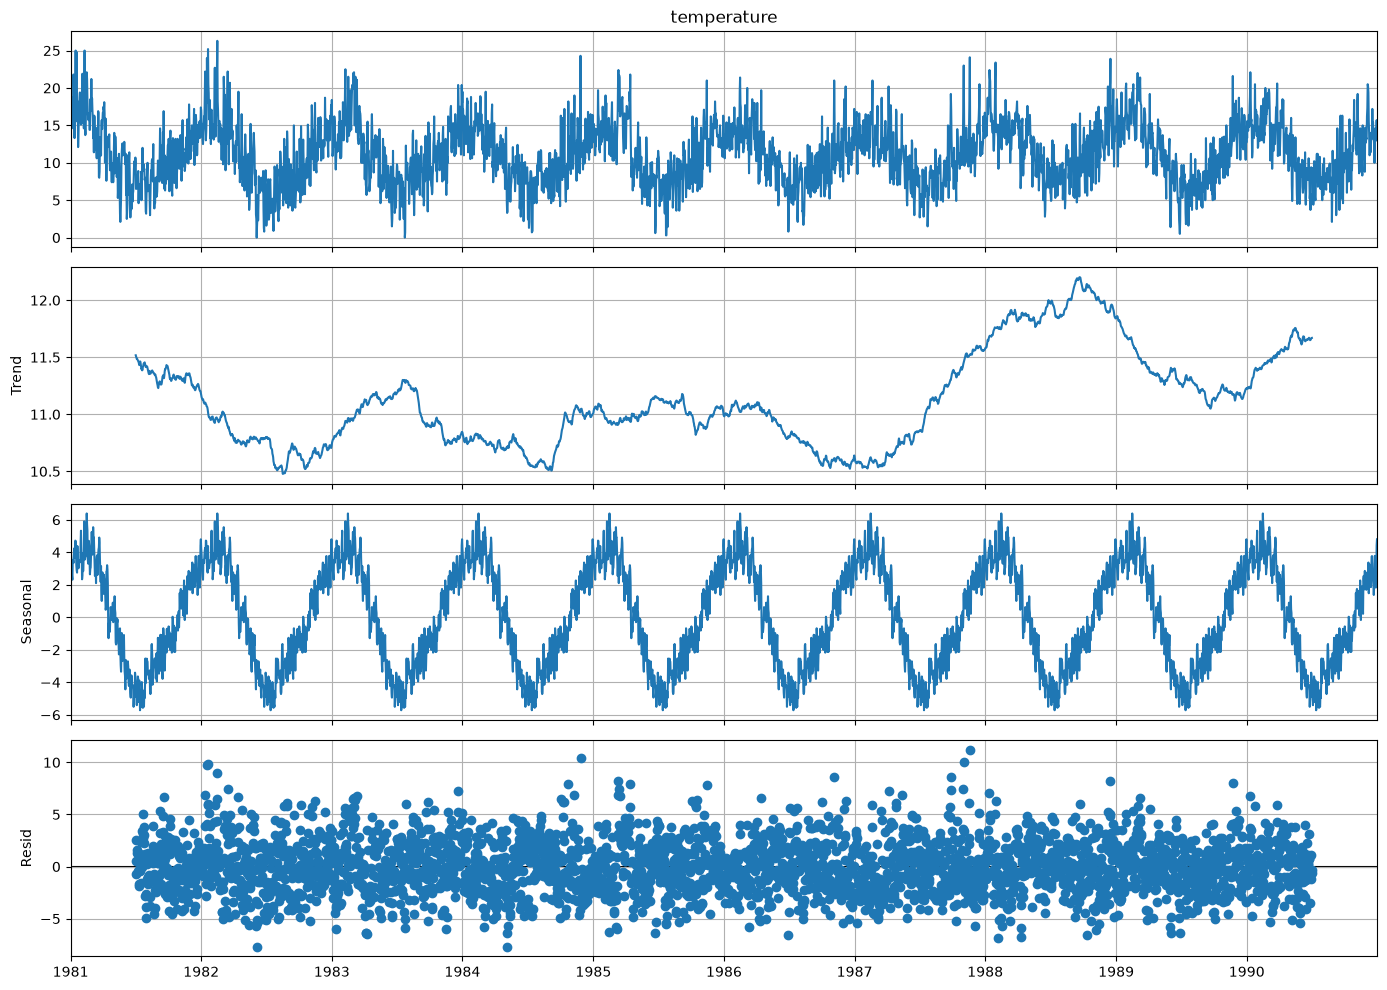

In [10]:
# Import the seasonal decomposition function
from statsmodels.tsa.seasonal import seasonal_decompose

# Decompose the daily temperature series
decomposition = seasonal_decompose(
    df["temperature"],
    model="additive",
    period=365
)

# Extract the individual components
trend = decomposition.trend
seasonal = decomposition.seasonal
residual = decomposition.resid

# Plot all components
fig = decomposition.plot()
fig.set_size_inches(14, 10)
plt.tight_layout()
plt.show()

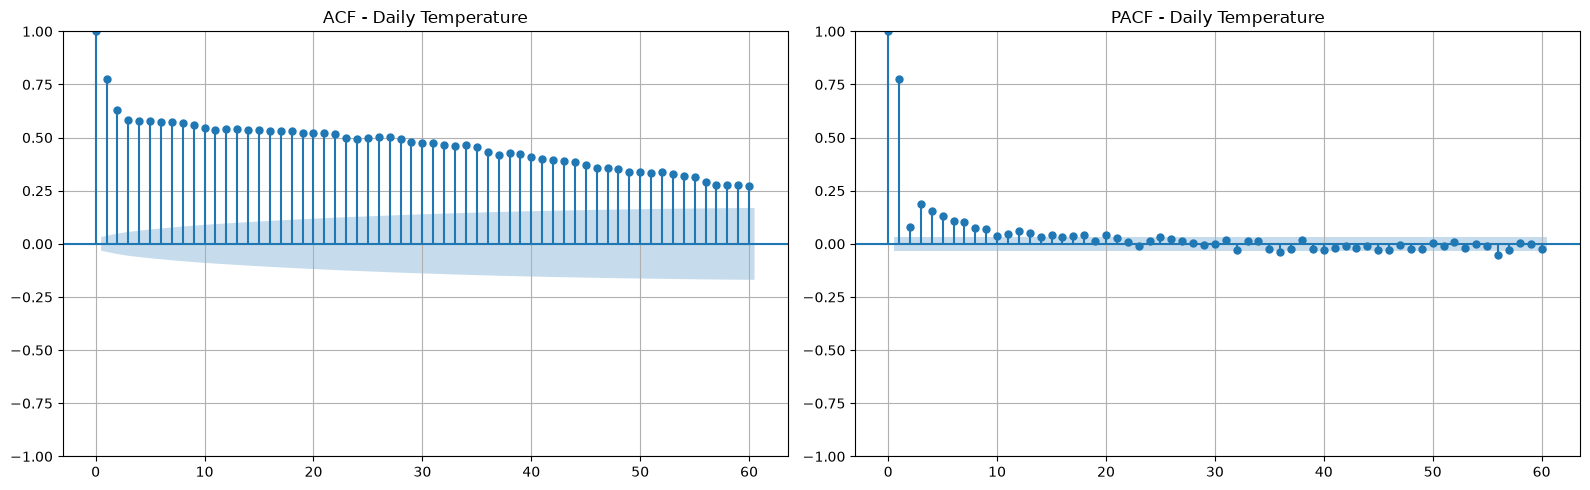

In [11]:
# Import ACF and PACF plotting functions
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

# Create two plots side by side
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# ACF: inspect autocorrelation across the first 60 daily lags
plot_acf(
    df["temperature"],
    lags=60,
    ax=axes[0]
)
axes[0].set_title("ACF - Daily Temperature")

# PACF: inspect partial autocorrelation across the first 60 lags
plot_pacf(
    df["temperature"],
    lags=60,
    method="ywm",
    ax=axes[1]
)
axes[1].set_title("PACF - Daily Temperature")

plt.tight_layout()
plt.show()

In [12]:
# Step 1: Define the forecast horizon
test_size = 365

# Step 2: Split the data chronologically
train = df["temperature"].iloc[:-test_size]
test = df["temperature"].iloc[-test_size:]

# Step 3: Display the split information
print("Training observations:", len(train))
print("Testing observations:", len(test))

print("\nTraining period:")
print("Start:", train.index.min())
print("End:", train.index.max())

print("\nTesting period:")
print("Start:", test.index.min())
print("End:", test.index.max())

Training observations: 3285
Testing observations: 365

Training period:
Start: 1981-01-01 00:00:00
End: 1989-12-31 00:00:00

Testing period:
Start: 1990-01-01 00:00:00
End: 1990-12-31 00:00:00


Seasonal Naive Baseline
MAE: 2.867
RMSE: 3.651


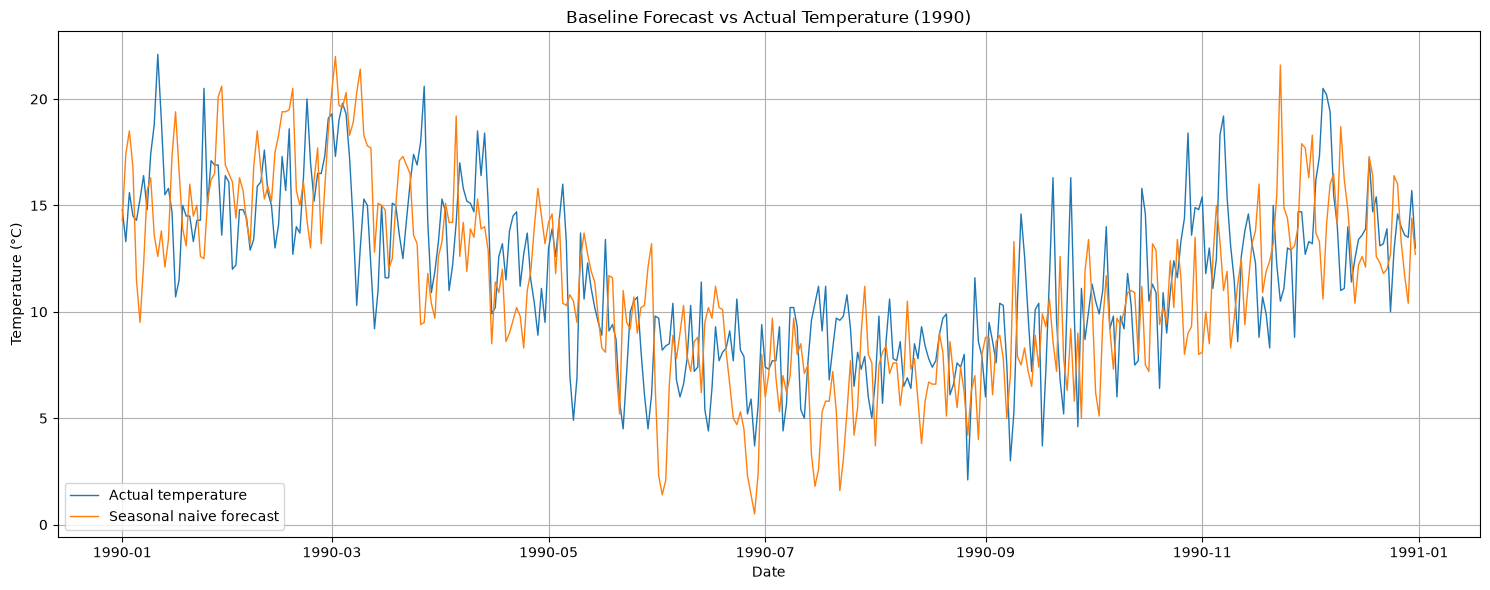

In [13]:
# Step 1: Define the seasonal period
seasonal_period = 365

# Step 2: Use the last 365 training observations as the seasonal pattern
seasonal_values = train.iloc[-seasonal_period:].to_numpy()

# Step 3: Forecast the next 365 days using that pattern
baseline_forecast = pd.Series(
    seasonal_values,
    index=test.index,
    name="Seasonal Naive Forecast"
)

# Step 4: Calculate evaluation metrics
from sklearn.metrics import mean_absolute_error, mean_squared_error

baseline_mae = mean_absolute_error(
    test,
    baseline_forecast
)

baseline_rmse = np.sqrt(
    mean_squared_error(test, baseline_forecast)
)

# Step 5: Display the baseline performance
print("Seasonal Naive Baseline")
print("MAE:", round(baseline_mae, 3))
print("RMSE:", round(baseline_rmse, 3))

# Step 6: Plot actual vs predicted temperatures
plt.figure(figsize=(15, 6))

plt.plot(
    test.index,
    test,
    label="Actual temperature",
    linewidth=1
)

plt.plot(
    baseline_forecast.index,
    baseline_forecast,
    label="Seasonal naive forecast",
    linewidth=1
)

plt.title("Baseline Forecast vs Actual Temperature (1990)")
plt.xlabel("Date")
plt.ylabel("Temperature (°C)")
plt.legend()
plt.tight_layout()
plt.show()

In [16]:
# Step 1: Import ARIMA and evaluation utilities
from statsmodels.tsa.arima.model import ARIMA
import warnings
from statsmodels.tools.sm_exceptions import ConvergenceWarning

# Step 2: Define candidate values for p, d, and q
p_values = range(0, 4)  # 0, 1, 2, 3
d_values = range(0, 2)  # 0, 1
q_values = range(0, 4)  # 0, 1, 2, 3

# Step 3: Store model results
arima_results = []

# Step 4: Try every combination
for p in p_values:
    for d in d_values:
        for q in q_values:

            order = (p, d, q)

            try:
                with warnings.catch_warnings():
                    warnings.simplefilter("ignore", ConvergenceWarning)
                    warnings.simplefilter("ignore", UserWarning)

                    model = ARIMA(
                        train_arima,
                        order=order
                    )

                    fitted_model = model.fit()

                # Save the model configuration and information criteria
                arima_results.append({
                    "p": p,
                    "d": d,
                    "q": q,
                    "AIC": fitted_model.aic,
                    "BIC": fitted_model.bic,
                    "Converged": fitted_model.mle_retvals.get(
                        "converged", None
                    )
                })

                print(
                    f"ARIMA{order} fitted | "
                    f"AIC: {fitted_model.aic:.2f} | "
                    f"BIC: {fitted_model.bic:.2f}"
                )

            except Exception as error:
                print(f"ARIMA{order} failed: {error}")

# Step 5: Convert results to a DataFrame
arima_results_df = pd.DataFrame(arima_results)

# Step 6: Rank models by AIC
arima_results_df = arima_results_df.sort_values(
    "AIC"
).reset_index(drop=True)

print("\nTop 10 ARIMA models ranked by AIC:")
display(arima_results_df.head(10))

ARIMA(0, 0, 0) fitted | AIC: 18575.34 | BIC: 18587.53
ARIMA(0, 0, 1) fitted | AIC: 16731.08 | BIC: 16749.37
ARIMA(0, 0, 2) fitted | AIC: 16194.61 | BIC: 16219.00
ARIMA(0, 0, 3) fitted | AIC: 15974.85 | BIC: 16005.34
ARIMA(0, 1, 0) fitted | AIC: 15956.51 | BIC: 15962.61
ARIMA(0, 1, 1) fitted | AIC: 15659.37 | BIC: 15671.56
ARIMA(0, 1, 2) fitted | AIC: 15177.20 | BIC: 15195.49
ARIMA(0, 1, 3) fitted | AIC: 15142.92 | BIC: 15167.30
ARIMA(1, 0, 0) fitted | AIC: 15574.40 | BIC: 15592.69
ARIMA(1, 0, 1) fitted | AIC: 15528.24 | BIC: 15552.63
ARIMA(1, 0, 2) fitted | AIC: 15173.03 | BIC: 15203.51
ARIMA(1, 0, 3) fitted | AIC: 15141.06 | BIC: 15177.64
ARIMA(1, 1, 0) fitted | AIC: 15844.69 | BIC: 15856.89
ARIMA(1, 1, 1) fitted | AIC: 15185.03 | BIC: 15203.32
ARIMA(1, 1, 2) fitted | AIC: 15143.67 | BIC: 15168.06
ARIMA(1, 1, 3) fitted | AIC: 15144.44 | BIC: 15174.93
ARIMA(2, 0, 0) fitted | AIC: 15554.85 | BIC: 15579.24
ARIMA(2, 0, 1) fitted | AIC: 15184.03 | BIC: 15214.51
ARIMA(2, 0, 2) fitted | AIC:

,p,d,q,AIC,BIC,Converged
0,3,0,1,15139.922917,15176.505648,True
1,1,0,3,15141.060038,15177.642769,True
2,2,1,1,15141.869804,15166.257074,True
3,2,0,2,15142.117011,15178.699742,True
4,2,0,3,15142.741498,15185.421351,True
5,0,1,3,15142.916866,15167.304136,True
6,3,0,3,15143.633441,15192.410416,True
7,1,1,2,15143.668654,15168.055924,True
8,2,1,2,15143.826546,15174.310634,True
9,3,1,1,15143.833342,15174.317429,True


In [17]:
# Step 1: Display the top 10 models
top_10_arima = arima_results_df.head(10).copy()

display(
    top_10_arima[
        ["p", "d", "q", "AIC", "BIC", "Converged"]
    ].round(3)
)

# Step 2: Identify the best model by AIC
best_aic_row = arima_results_df.loc[
    arima_results_df["AIC"].idxmin()
]

print("Best ARIMA order by AIC:")
print(
    f"ARIMA({int(best_aic_row['p'])}, "
    f"{int(best_aic_row['d'])}, "
    f"{int(best_aic_row['q'])})"
)

print("Best AIC:", round(best_aic_row["AIC"], 3))
print("Corresponding BIC:", round(best_aic_row["BIC"], 3))

# Step 3: Identify the best model by BIC
best_bic_row = arima_results_df.loc[
    arima_results_df["BIC"].idxmin()
]

print("\nBest ARIMA order by BIC:")
print(
    f"ARIMA({int(best_bic_row['p'])}, "
    f"{int(best_bic_row['d'])}, "
    f"{int(best_bic_row['q'])})"
)

print("Best BIC:", round(best_bic_row["BIC"], 3))

,p,d,q,AIC,BIC,Converged
0,3,0,1,15139.923,15176.506,True
1,1,0,3,15141.060,15177.643,True
2,2,1,1,15141.870,15166.257,True
3,2,0,2,15142.117,15178.700,True
4,2,0,3,15142.741,15185.421,True
5,0,1,3,15142.917,15167.304,True
6,3,0,3,15143.633,15192.410,True
7,1,1,2,15143.669,15168.056,True
8,2,1,2,15143.827,15174.311,True
9,3,1,1,15143.833,15174.317,True


Best ARIMA order by AIC:
ARIMA(3, 0, 1)
Best AIC: 15139.923
Corresponding BIC: 15176.506

Best ARIMA order by BIC:
ARIMA(2, 1, 1)
Best BIC: 15166.257


Selected ARIMA order: (3, 0, 1)

ARIMA Evaluation Results
MAE: 3.071
RMSE: 3.694


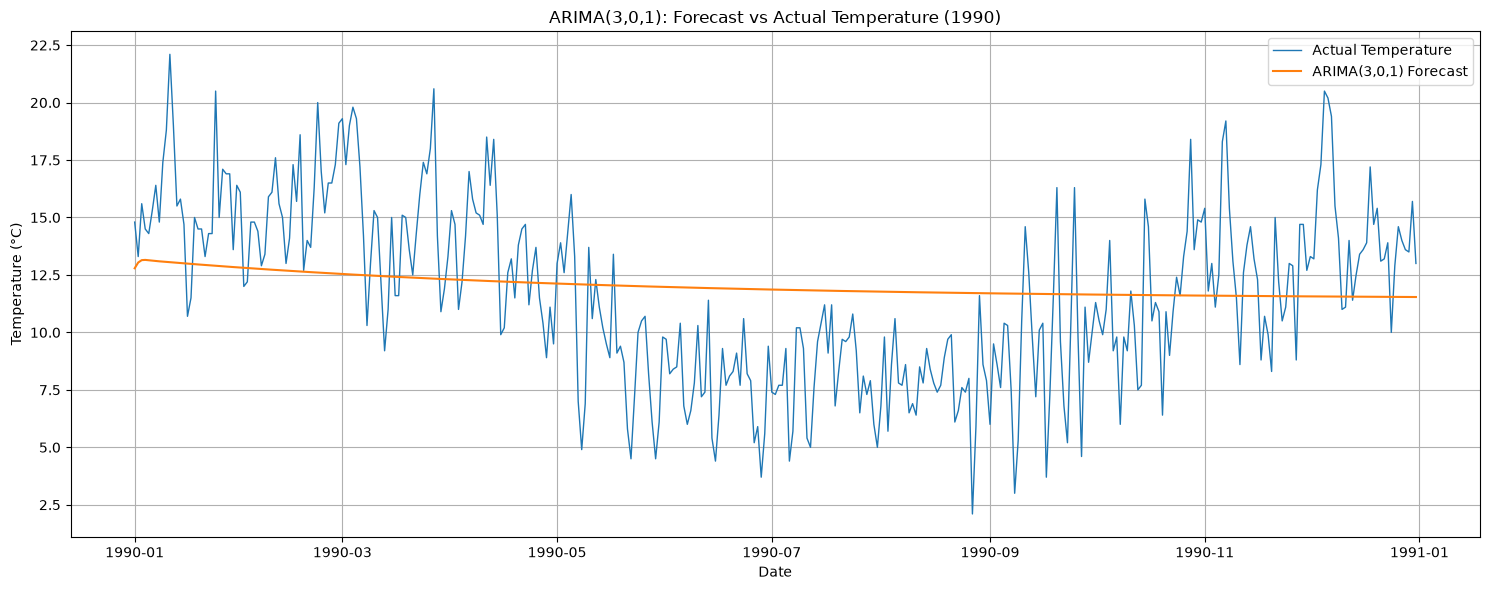

,Actual Temperature,Predicted Temperature
date,,
1990-01-01,14.8,12.79
1990-01-02,13.3,13.04
1990-01-03,15.6,13.14
1990-01-04,14.5,13.15
1990-01-05,14.3,13.14
1990-01-06,15.3,13.12
1990-01-07,16.4,13.11
1990-01-08,14.8,13.09
1990-01-09,17.4,13.08


In [18]:
# Step 1: Import ARIMA
from statsmodels.tsa.arima.model import ARIMA

# Step 2: Set the best parameters from our grid search
best_order = (3, 0, 1)

print("Selected ARIMA order:", best_order)

# Step 3: Fit ARIMA on the training data
arima_model = ARIMA(
    train_arima,
    order=best_order
)

arima_result = arima_model.fit()

# Step 4: Forecast the entire test period (365 days)
forecast_values = arima_result.forecast(
    steps=len(test)
)

# Step 5: Align predictions with actual test dates
arima_forecast = pd.Series(
    np.asarray(forecast_values),
    index=test.index,
    name="ARIMA(3,0,1) Forecast"
)

# Step 6: Calculate evaluation metrics
arima_mae = mean_absolute_error(
    test,
    arima_forecast
)

arima_rmse = np.sqrt(
    mean_squared_error(
        test,
        arima_forecast
    )
)

print("\nARIMA Evaluation Results")
print("MAE:", round(arima_mae, 3))
print("RMSE:", round(arima_rmse, 3))

# Step 7: Plot actual vs predicted temperatures
plt.figure(figsize=(15, 6))

plt.plot(
    test.index,
    test,
    label="Actual Temperature",
    linewidth=1
)

plt.plot(
    arima_forecast.index,
    arima_forecast,
    label="ARIMA(3,0,1) Forecast",
    linewidth=1.5
)

plt.title("ARIMA(3,0,1): Forecast vs Actual Temperature (1990)")
plt.xlabel("Date")
plt.ylabel("Temperature (°C)")
plt.legend()
plt.tight_layout()
plt.show()

# Step 8: Display sample predictions
forecast_comparison = pd.DataFrame({
    "Actual Temperature": test,
    "Predicted Temperature": arima_forecast
})

display(forecast_comparison.head(10).round(2))

In [19]:

# Split the existing training data chronologically.
# The final 365 days of the training period will be used for validation.

validation_size = 365

sarima_train = train.iloc[:-validation_size].copy()
sarima_validation = train.iloc[-validation_size:].copy()

# Ensure a regular daily datetime index for SARIMAX.
sarima_train.index = pd.date_range(
    start=sarima_train.index[0],
    periods=len(sarima_train),
    freq="D"
)

sarima_validation.index = pd.date_range(
    start=sarima_train.index[-1] + pd.Timedelta(days=1),
    periods=len(sarima_validation),
    freq="D"
)

print("SARIMA training period:", sarima_train.index.min(), "to", sarima_train.index.max())
print("Validation period:", sarima_validation.index.min(), "to", sarima_validation.index.max())
print("Training observations:", len(sarima_train))
print("Validation observations:", len(sarima_validation))


SARIMA training period: 1981-01-01 00:00:00 to 1988-12-29 00:00:00
Validation period: 1988-12-30 00:00:00 to 1989-12-29 00:00:00
Training observations: 2920
Validation observations: 365


In [21]:

from statsmodels.tsa.statespace.sarimax import SARIMAX

# Reuse the best ARIMA parameters selected by AIC
best_arima_order = (3, 0, 1)

# Add seasonal parameters
seasonal_order = (1, 0, 1, 7)

sarima_model = SARIMAX(
    sarima_train,
    order=best_arima_order,
    seasonal_order=seasonal_order,
    enforce_stationarity=False,
    enforce_invertibility=False
)

sarima_result = sarima_model.fit(disp=False, maxiter=200)

print("Non-seasonal order:", best_arima_order)
print("Seasonal order:", seasonal_order)
print("AIC:", round(sarima_result.aic, 3))
print(sarima_result.summary())


Non-seasonal order: (3, 0, 1)
Seasonal order: (1, 0, 1, 7)
AIC: 13499.932
                                     SARIMAX Results                                     
Dep. Variable:                       temperature   No. Observations:                 2920
Model:             SARIMAX(3, 0, 1)x(1, 0, 1, 7)   Log Likelihood               -6742.966
Date:                           Sun, 11 Oct 2026   AIC                          13499.932
Time:                                   11:49:24   BIC                          13541.763
Sample:                               01-01-1981   HQIC                         13515.002
                                    - 12-29-1988                                         
Covariance Type:                             opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          1.4883      0.020     75.450     

SARIMA Validation Results
MAE: 3.612
RMSE: 4.439


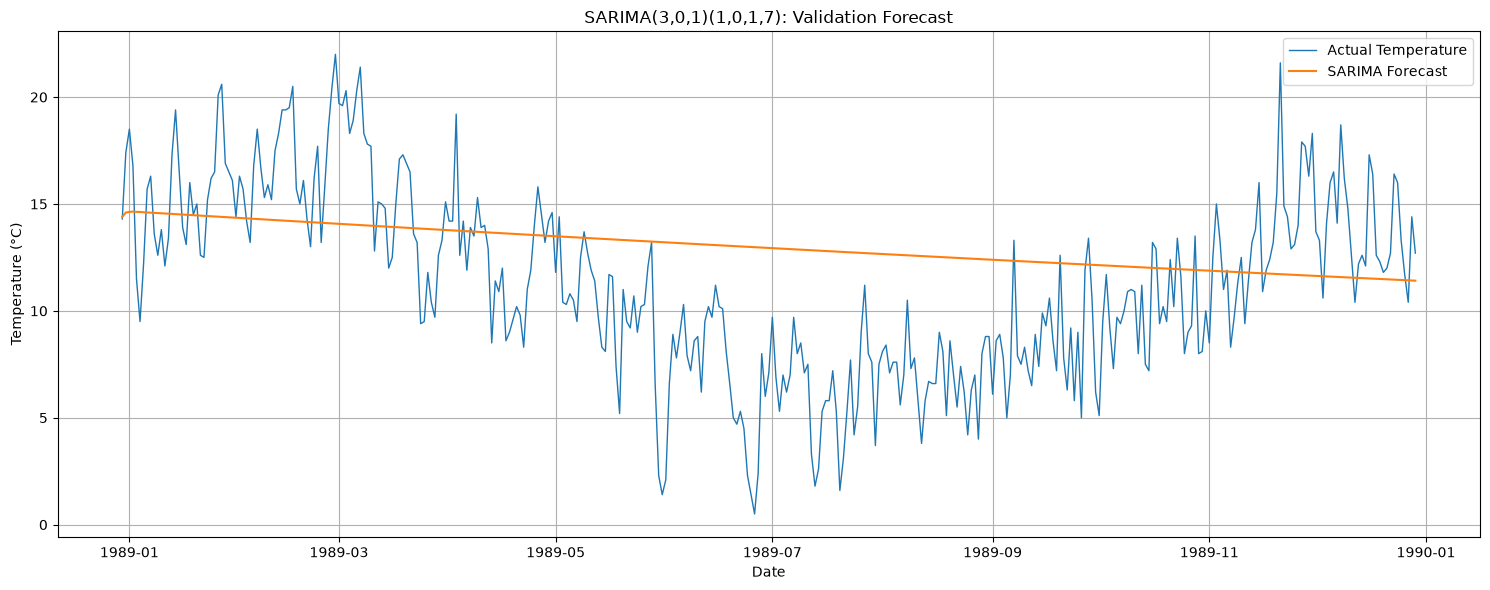

In [22]:

# Forecast the validation period
sarima_validation_forecast_values = sarima_result.forecast(
    steps=len(sarima_validation)
)

sarima_validation_forecast = pd.Series(
    np.asarray(sarima_validation_forecast_values),
    index=sarima_validation.index,
    name="SARIMA Forecast"
)

# Calculate validation metrics
sarima_validation_mae = mean_absolute_error(
    sarima_validation,
    sarima_validation_forecast
)

sarima_validation_rmse = np.sqrt(
    mean_squared_error(
        sarima_validation,
        sarima_validation_forecast
    )
)

print("SARIMA Validation Results")
print("MAE:", round(sarima_validation_mae, 3))
print("RMSE:", round(sarima_validation_rmse, 3))

# Plot actual vs predicted temperatures
plt.figure(figsize=(15, 6))

plt.plot(
    sarima_validation.index,
    sarima_validation,
    label="Actual Temperature",
    linewidth=1
)

plt.plot(
    sarima_validation_forecast.index,
    sarima_validation_forecast,
    label="SARIMA Forecast",
    linewidth=1.5
)

plt.title("SARIMA(3,0,1)(1,0,1,7): Validation Forecast")
plt.xlabel("Date")
plt.ylabel("Temperature (°C)")
plt.legend()
plt.tight_layout()
plt.show()


In [23]:

# Weekly seasonal-naive forecast for the validation period
weekly_values = sarima_train.iloc[-7:].to_numpy()
weekly_forecast_values = np.resize(weekly_values, len(sarima_validation))

weekly_forecast = pd.Series(
    weekly_forecast_values,
    index=sarima_validation.index,
    name="Weekly Seasonal Naive"
)

weekly_mae = mean_absolute_error(
    sarima_validation, weekly_forecast
)

weekly_rmse = np.sqrt(
    mean_squared_error(sarima_validation, weekly_forecast)
)

print("Weekly Seasonal Naive Validation Results")
print("MAE:", round(weekly_mae, 3))
print("RMSE:", round(weekly_rmse, 3))


Weekly Seasonal Naive Validation Results
MAE: 4.89
RMSE: 6.039


In [24]:

# Annual seasonal-naive forecast for the validation period.
# Use the corresponding day from the previous year where available.

annual_values = sarima_train.iloc[-365:].to_numpy()

annual_forecast = pd.Series(
    annual_values,
    index=sarima_validation.index,
    name="Annual Seasonal Naive"
)

annual_mae = mean_absolute_error(
    sarima_validation,
    annual_forecast
)

annual_rmse = np.sqrt(
    mean_squared_error(sarima_validation, annual_forecast)
)

print("Annual Seasonal Naive Validation Results")
print("MAE:", round(annual_mae, 3))
print("RMSE:", round(annual_rmse, 3))


Annual Seasonal Naive Validation Results
MAE: 3.064
RMSE: 3.803


In [25]:

def make_fourier_features(index, period=365.25, K=5):
    """
    Create Fourier features for annual seasonality.

    period: approximate number of days per year
    K: number of sine/cosine harmonic pairs
    """
    # Days elapsed from the start of the series
    time = (index - pd.Timestamp("1981-01-01")).days.to_numpy()

    features = pd.DataFrame(index=index)

    for k in range(1, K + 1):
        features[f"sin_{k}"] = np.sin(2 * np.pi * k * time / period)
        features[f"cos_{k}"] = np.cos(2 * np.pi * k * time / period)

    return features


# Build features for training and validation dates
fourier_train = make_fourier_features(sarima_train.index, period=365.25, K=5)
fourier_validation = make_fourier_features(
    sarima_validation.index, period=365.25, K=5
)

print("Training feature shape:", fourier_train.shape)
print("Validation feature shape:", fourier_validation.shape)

display(fourier_train.head())


Training feature shape: (2920, 10)
Validation feature shape: (365, 10)


,sin_1,cos_1,sin_2,cos_2,sin_3,cos_3,sin_4,cos_4,sin_5,cos_5
1981-01-01,0.000000,1.000000,0.000000,1.000000,0.000000,1.000000,0.000000,1.000000,0.000000,1.000000
1981-01-02,0.017202,0.999852,0.034398,0.999408,0.051584,0.998669,0.068755,0.997634,0.085906,0.996303
1981-01-03,0.034398,0.999408,0.068755,0.997634,0.103031,0.994678,0.137185,0.990545,0.171177,0.985240
1981-01-04,0.051584,0.998669,0.103031,0.994678,0.154204,0.988039,0.204966,0.978769,0.255182,0.966893
1981-01-05,0.068755,0.997634,0.137185,0.990545,0.204966,0.978769,0.271777,0.962360,0.337301,0.941397


Fourier + ARIMA(3,0,1) Validation Results
MAE: 2.064
RMSE: 2.594


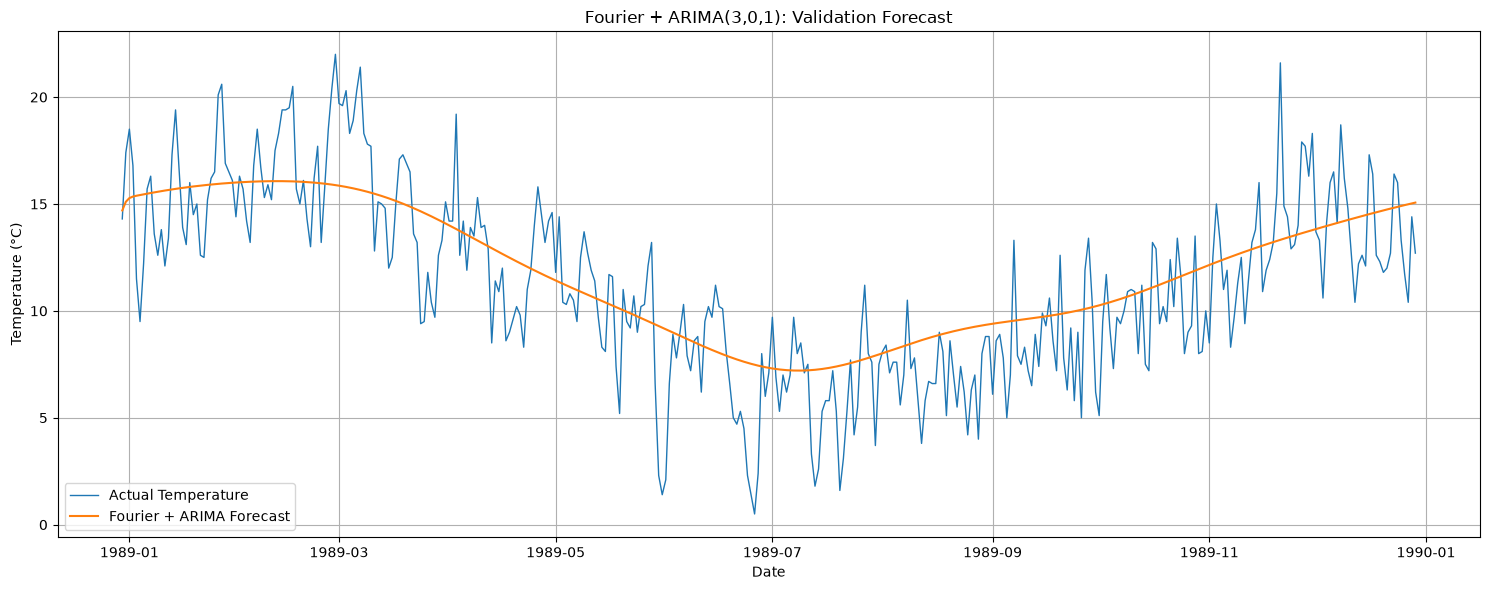

In [26]:

from statsmodels.tsa.statespace.sarimax import SARIMAX

fourier_arima_model = SARIMAX(
    sarima_train,
    exog=fourier_train,
    order=(3, 0, 1),
    seasonal_order=(0, 0, 0, 0),
    enforce_stationarity=False,
    enforce_invertibility=False
)

fourier_arima_result = fourier_arima_model.fit(
    disp=False,
    maxiter=200
)

# Forecast the validation period using its known future calendar features
fourier_forecast_values = fourier_arima_result.forecast(
    steps=len(sarima_validation),
    exog=fourier_validation
)

fourier_forecast = pd.Series(
    np.asarray(fourier_forecast_values),
    index=sarima_validation.index,
    name="Fourier + ARIMA Forecast"
)

# Evaluate validation performance
fourier_mae = mean_absolute_error(
    sarima_validation,
    fourier_forecast
)

fourier_rmse = np.sqrt(
    mean_squared_error(sarima_validation, fourier_forecast)
)

print("Fourier + ARIMA(3,0,1) Validation Results")
print("MAE:", round(fourier_mae, 3))
print("RMSE:", round(fourier_rmse, 3))

# Plot actual and forecast temperatures
plt.figure(figsize=(15, 6))

plt.plot(
    sarima_validation.index,
    sarima_validation,
    label="Actual Temperature",
    linewidth=1
)

plt.plot(
    fourier_forecast.index,
    fourier_forecast,
    label="Fourier + ARIMA Forecast",
    linewidth=1.5
)

plt.title("Fourier + ARIMA(3,0,1): Validation Forecast")
plt.xlabel("Date")
plt.ylabel("Temperature (°C)")
plt.legend()
plt.tight_layout()
plt.show()


In [27]:

fourier_tuning_results = []

for K in [1, 2, 3, 5, 8]:
    X_train = make_fourier_features(
        sarima_train.index, period=365.25, K=K
    )
    X_validation = make_fourier_features(
        sarima_validation.index, period=365.25, K=K
    )

    model = SARIMAX(
        sarima_train,
        exog=X_train,
        order=(3, 0, 1),
        seasonal_order=(0, 0, 0, 0),
        enforce_stationarity=False,
        enforce_invertibility=False
    )

    result = model.fit(disp=False, maxiter=200)

    forecast = result.forecast(
        steps=len(sarima_validation),
        exog=X_validation
    )

    forecast = pd.Series(
        np.asarray(forecast),
        index=sarima_validation.index
    )

    fourier_tuning_results.append({
        "K": K,
        "Number_of_features": 2 * K,
        "AIC": result.aic,
        "Validation_MAE": mean_absolute_error(
            sarima_validation, forecast
        ),
        "Validation_RMSE": np.sqrt(
            mean_squared_error(sarima_validation, forecast)
        )
    })

fourier_tuning_df = (
    pd.DataFrame(fourier_tuning_results)
    .sort_values("Validation_RMSE")
    .reset_index(drop=True)
)

display(fourier_tuning_df.round(3))


d:\Capstone project 2\myenv\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(


,K,Number_of_features,AIC,Validation_MAE,Validation_RMSE
0,2,4,13657.629,2.004,2.539
1,1,2,13430.294,2.017,2.583
2,5,10,13417.041,2.064,2.594
3,8,16,13426.772,2.069,2.603
4,3,6,13414.731,2.077,2.617


In [28]:

best_K = 2

best_fourier_train = make_fourier_features(
    sarima_train.index,
    period=365.25,
    K=best_K
)

best_fourier_validation = make_fourier_features(
    sarima_validation.index,
    period=365.25,
    K=best_K
)

best_fourier_model = SARIMAX(
    sarima_train,
    exog=best_fourier_train,
    order=(3, 0, 1),
    seasonal_order=(0, 0, 0, 0),
    enforce_stationarity=False,
    enforce_invertibility=False
)

best_fourier_result = best_fourier_model.fit(
    disp=False,
    maxiter=500
)

best_fourier_forecast = best_fourier_result.forecast(
    steps=len(sarima_validation),
    exog=best_fourier_validation
)

best_fourier_forecast = pd.Series(
    np.asarray(best_fourier_forecast),
    index=sarima_validation.index,
    name="Fourier ARIMA K=2"
)

print("Selected K:", best_K)
print("Converged:", best_fourier_result.mle_retvals.get("converged"))
print("AIC:", round(best_fourier_result.aic, 3))
print(
    "Validation MAE:",
    round(mean_absolute_error(
        sarima_validation, best_fourier_forecast
    ), 3)
)
print(
    "Validation RMSE:",
    round(np.sqrt(mean_squared_error(
        sarima_validation, best_fourier_forecast
    )), 3)
)


Selected K: 2
Converged: False
AIC: 13657.629
Validation MAE: 2.004
Validation RMSE: 2.539


d:\Capstone project 2\myenv\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(


In [29]:

print("Convergence diagnostics")
print("-----------------------")
print("Converged:", best_fourier_result.mle_retvals.get("converged"))
print("Optimizer message:", best_fourier_result.mle_retvals.get("message"))
print("Iterations:", best_fourier_result.mle_retvals.get("iterations"))

print("\nEstimated parameters:")
display(best_fourier_result.params)

print("\nParameter standard errors:")
display(best_fourier_result.bse)

print("\nGradient information:")
print(best_fourier_result.mle_retvals.get("gopt"))


Convergence diagnostics
-----------------------
Converged: False
Optimizer message: None
Iterations: 22

Estimated parameters:


sin_1     1.612069
cos_1     3.776298
sin_2     0.403783
cos_2    -0.419116
ar.L1     1.696316
ar.L2    -0.793171
ar.L3     0.096857
ma.L1    -0.998996
sigma2    8.326716
dtype: float64


Parameter standard errors:


sin_1     0.221913
cos_1     0.244997
sin_2     0.229851
cos_2     0.223731
ar.L1     0.023859
ar.L2     0.042592
ar.L3     0.025596
ma.L1     0.002090
sigma2    0.291298
dtype: float64


Gradient information:
[-6.35133723e-05 -6.35903330e-05 -3.52086804e-05 -6.26724894e-05
  1.20076685e+01  1.18680825e+01  1.18064398e+01 -1.79783406e-01
  9.81684854e-02]


In [30]:

fourier_order_results = []

for order in [(0, 0, 0), (1, 0, 0), (2, 0, 0), (1, 0, 1), (2, 0, 1)]:
    try:
        with warnings.catch_warnings():
            warnings.simplefilter("ignore")

            model = SARIMAX(
                sarima_train,
                exog=best_fourier_train,
                order=order,
                seasonal_order=(0, 0, 0, 0),
                enforce_stationarity=True,
                enforce_invertibility=True
            )

            result = model.fit(disp=False, maxiter=500)

        forecast = result.forecast(
            steps=len(sarima_validation),
            exog=best_fourier_validation
        )

        forecast = np.asarray(forecast)

        fourier_order_results.append({
            "ARIMA_Order": order,
            "Converged": result.mle_retvals.get("converged"),
            "AIC": result.aic,
            "Validation_MAE": mean_absolute_error(
                sarima_validation, forecast
            ),
            "Validation_RMSE": np.sqrt(
                mean_squared_error(sarima_validation, forecast)
            )
        })

    except Exception as error:
        print(f"Order {order} failed: {error}")

fourier_order_df = pd.DataFrame(fourier_order_results)
fourier_order_df = fourier_order_df.sort_values(
    "Validation_RMSE"
).reset_index(drop=True)

display(fourier_order_df.round(3))


,ARIMA_Order,Converged,AIC,Validation_MAE,Validation_RMSE
0,"(2, 0, 1)",True,13454.162,2.078,2.621
1,"(1, 0, 1)",True,14001.526,6.459,7.121
2,"(2, 0, 0)",True,14159.503,9.962,10.452
3,"(1, 0, 0)",True,14247.510,10.370,10.819
4,"(0, 0, 0)",True,22537.212,11.264,11.547


d:\Capstone project 2\myenv\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:679: EstimationWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.
  start_params = self.start_params
d:\Capstone project 2\myenv\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:679: EstimationWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  start_params = self.start_params


Selected ARIMA order: (2, 0, 1)
Converged: True
AIC: 13454.162


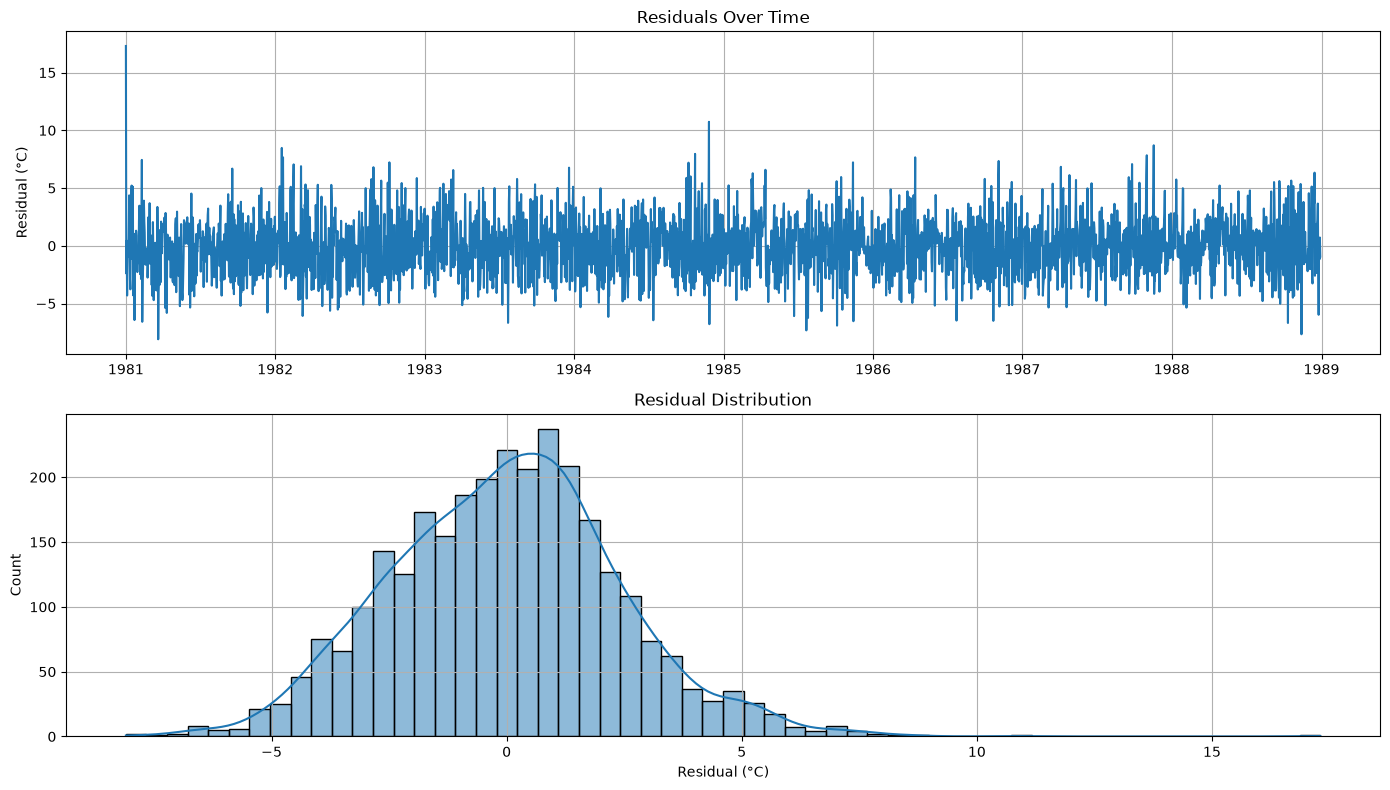

In [31]:

# Fit the selected converged Fourier + ARIMA model
best_order = (2, 0, 1)

final_candidate_model = SARIMAX(
    sarima_train,
    exog=best_fourier_train,
    order=best_order,
    seasonal_order=(0, 0, 0, 0),
    enforce_stationarity=True,
    enforce_invertibility=True
)

final_candidate_result = final_candidate_model.fit(
    disp=False,
    maxiter=500
)

print("Selected ARIMA order:", best_order)
print("Converged:", final_candidate_result.mle_retvals.get("converged"))
print("AIC:", round(final_candidate_result.aic, 3))

# Plot residuals
residuals = final_candidate_result.resid

fig, axes = plt.subplots(2, 1, figsize=(14, 8))

axes[0].plot(residuals.index, residuals)
axes[0].set_title("Residuals Over Time")
axes[0].set_ylabel("Residual (°C)")

sns.histplot(residuals, kde=True, ax=axes[1])
axes[1].set_title("Residual Distribution")
axes[1].set_xlabel("Residual (°C)")

plt.tight_layout()
plt.show()


Ljung-Box Test Results


,lb_stat,lb_pvalue
7,33.2575,0.0000
14,37.3834,0.0006
30,50.9610,0.0098


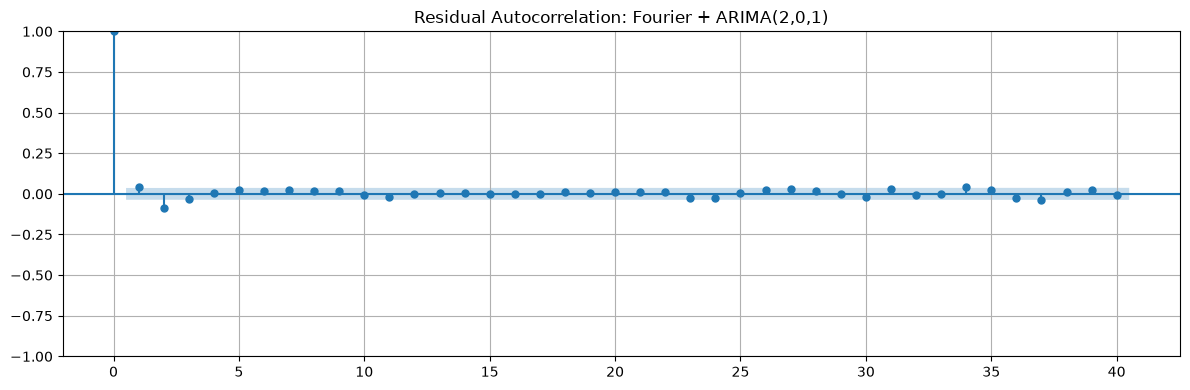

In [32]:

from statsmodels.stats.diagnostic import acorr_ljungbox
from statsmodels.graphics.tsaplots import plot_acf

residuals = final_candidate_result.resid

# Test residual autocorrelation at multiple lags
ljung_box_results = acorr_ljungbox(
    residuals,
    lags=[7, 14, 30],
    return_df=True
)

print("Ljung-Box Test Results")
display(ljung_box_results.round(4))

# Plot residual ACF to inspect remaining dependence
fig, ax = plt.subplots(figsize=(12, 4))

plot_acf(residuals, lags=40, ax=ax)
ax.set_title("Residual Autocorrelation: Fourier + ARIMA(2,0,1)")

plt.tight_layout()
plt.show()


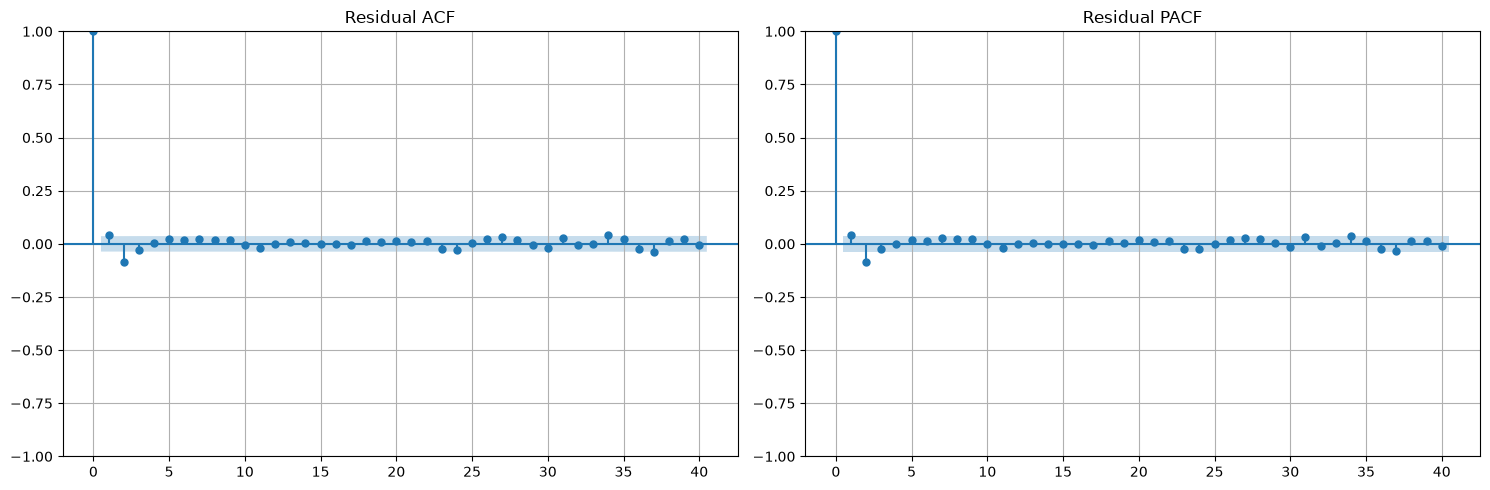

In [33]:

from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

residuals = final_candidate_result.resid

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

plot_acf(residuals, lags=40, ax=axes[0])
axes[0].set_title("Residual ACF")

plot_pacf(residuals, lags=40, method="ywm", ax=axes[1])
axes[1].set_title("Residual PACF")

plt.tight_layout()
plt.show()


In [34]:

fourier_arima301_model = SARIMAX(
    sarima_train,
    exog=best_fourier_train,
    order=(3, 0, 1),
    seasonal_order=(0, 0, 0, 0),
    enforce_stationarity=True,
    enforce_invertibility=True
)

fourier_arima301_result = fourier_arima301_model.fit(
    disp=False,
    maxiter=500
)

forecast_301 = fourier_arima301_result.forecast(
    steps=len(sarima_validation),
    exog=best_fourier_validation
)

forecast_301 = np.asarray(forecast_301)

print("Converged:", fourier_arima301_result.mle_retvals.get("converged"))
print("AIC:", round(fourier_arima301_result.aic, 3))
print("Validation MAE:", round(
    mean_absolute_error(sarima_validation, forecast_301), 3
))
print("Validation RMSE:", round(
    np.sqrt(mean_squared_error(sarima_validation, forecast_301)), 3
))


Converged: True
AIC: 13429.053
Validation MAE: 2.085
Validation RMSE: 2.628


d:\Capstone project 2\myenv\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:679: EstimationWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.
  start_params = self.start_params
d:\Capstone project 2\myenv\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:679: EstimationWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  start_params = self.start_params


Converged: True

FINAL TEST RESULTS — 1990
MAE: 1.95 °C
RMSE: 2.54 °C

ANNUAL SEASONAL-NAIVE BASELINE
MAE: 2.867 °C
RMSE: 3.651 °C


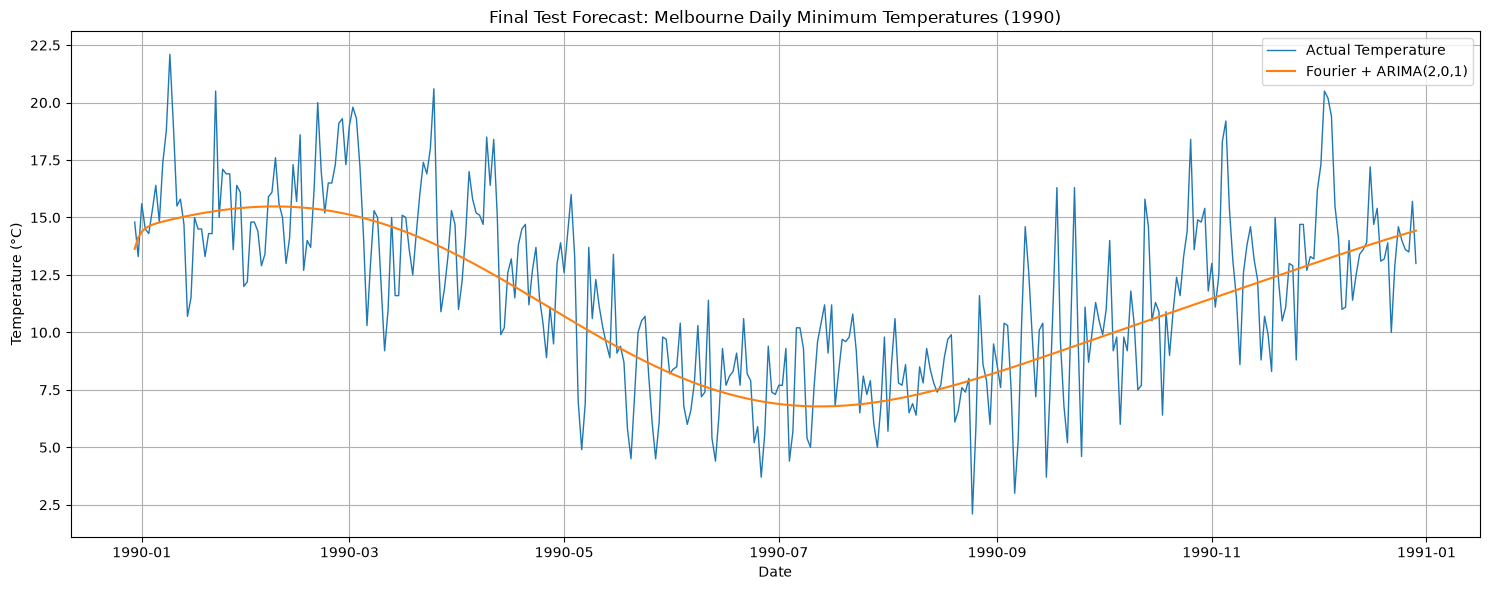

In [35]:

# Refit the selected model on all available training data (1981–1989)
final_train = train.copy()

final_train.index = pd.date_range(
    start=final_train.index[0],
    periods=len(final_train),
    freq="D"
)

final_test = test.copy()

final_test.index = pd.date_range(
    start=final_train.index[-1] + pd.Timedelta(days=1),
    periods=len(final_test),
    freq="D"
)

# Build Fourier features using the same reference date and K=2
final_fourier_train = make_fourier_features(
    final_train.index, period=365.25, K=2
)

final_fourier_test = make_fourier_features(
    final_test.index, period=365.25, K=2
)

# Fit the selected Fourier + ARIMA model
final_model = SARIMAX(
    final_train,
    exog=final_fourier_train,
    order=(2, 0, 1),
    seasonal_order=(0, 0, 0, 0),
    enforce_stationarity=True,
    enforce_invertibility=True
)

final_result = final_model.fit(disp=False, maxiter=500)

print("Converged:", final_result.mle_retvals.get("converged"))

# Forecast the 1990 test year
final_forecast_values = final_result.forecast(
    steps=len(final_test),
    exog=final_fourier_test
)

final_forecast = pd.Series(
    np.asarray(final_forecast_values),
    index=final_test.index,
    name="Fourier + ARIMA Forecast"
)

# Calculate final test metrics
final_mae = mean_absolute_error(final_test, final_forecast)
final_rmse = np.sqrt(mean_squared_error(final_test, final_forecast))

print("\nFINAL TEST RESULTS — 1990")
print("MAE:", round(final_mae, 3), "°C")
print("RMSE:", round(final_rmse, 3), "°C")

# Annual seasonal-naive baseline on the same test dates
annual_baseline = pd.Series(
    train.iloc[-365:].to_numpy(),
    index=final_test.index,
    name="Annual Seasonal Naive"
)

baseline_test_mae = mean_absolute_error(final_test, annual_baseline)
baseline_test_rmse = np.sqrt(
    mean_squared_error(final_test, annual_baseline)
)

print("\nANNUAL SEASONAL-NAIVE BASELINE")
print("MAE:", round(baseline_test_mae, 3), "°C")
print("RMSE:", round(baseline_test_rmse, 3), "°C")

# Plot actual vs forecast
plt.figure(figsize=(15, 6))
plt.plot(final_test.index, final_test, label="Actual Temperature", linewidth=1)
plt.plot(final_forecast.index, final_forecast, label="Fourier + ARIMA(2,0,1)", linewidth=1.5)
plt.title("Final Test Forecast: Melbourne Daily Minimum Temperatures (1990)")
plt.xlabel("Date")
plt.ylabel("Temperature (°C)")
plt.legend()
plt.tight_layout()
plt.show()


In [36]:

model_comparison = pd.DataFrame([
    {
        "Model": "Seasonal Naive (annual)",
        "Validation MAE": annual_mae,
        "Validation RMSE": annual_rmse,
        "Test MAE": baseline_test_mae,
        "Test RMSE": baseline_test_rmse
    },
    {
        "Model": "SARIMA(3,0,1)(1,0,1,7)",
        "Validation MAE": sarima_validation_mae,
        "Validation RMSE": sarima_validation_rmse,
        "Test MAE": np.nan,
        "Test RMSE": np.nan
    },
    {
        "Model": "Fourier + ARIMA(2,0,1), K=2",
        "Validation MAE": 2.078,
        "Validation RMSE": 2.621,
        "Test MAE": final_mae,
        "Test RMSE": final_rmse
    }
])

display(
    model_comparison
    .sort_values("Validation RMSE")
    .reset_index(drop=True)
    .round(3)
)


,Model,Validation MAE,Validation RMSE,Test MAE,Test RMSE
0,"Fourier + ARIMA(2,0,1), K=2",2.078,2.621,1.950,2.540
1,Seasonal Naive (annual),3.064,3.803,2.867,3.651
2,"SARIMA(3,0,1)(1,0,1,7)",3.612,4.439,NaN,NaN


In [37]:

from sklearn.preprocessing import MinMaxScaler

# Use the original daily temperature series
temperature_series = df["temperature"].copy()

# Chronological split: reserve 1990 as test data
lstm_train = temperature_series.loc[:"1989-12-31"].copy()
lstm_test = temperature_series.loc["1990-01-01":].copy()

# Fit the scaler on training data only to prevent leakage
scaler = MinMaxScaler(feature_range=(0, 1))

train_scaled = scaler.fit_transform(
    lstm_train.to_numpy().reshape(-1, 1)
)

test_scaled = scaler.transform(
    lstm_test.to_numpy().reshape(-1, 1)
)

print("Training observations:", len(lstm_train))
print("Test observations:", len(lstm_test))
print("Sequence length: 30 days")
print("Training scaled shape:", train_scaled.shape)
print("Test scaled shape:", test_scaled.shape)


Training observations: 3285
Test observations: 365
Sequence length: 30 days
Training scaled shape: (3285, 1)
Test scaled shape: (365, 1)


In [38]:

def create_sequences(data, sequence_length=30):
    X, y = [], []

    for i in range(sequence_length, len(data)):
        X.append(data[i - sequence_length:i, 0])
        y.append(data[i, 0])

    X = np.array(X).reshape(-1, sequence_length, 1)
    y = np.array(y)

    return X, y


sequence_length = 30

X_train, y_train = create_sequences(
    train_scaled, sequence_length
)

# Include the final 30 training days as context for the first test prediction
test_with_context = np.vstack([
    train_scaled[-sequence_length:],
    test_scaled
])

X_test, y_test = create_sequences(
    test_with_context, sequence_length
)

print("X_train shape:", X_train.shape)
print("y_train shape:", y_train.shape)
print("X_test shape:", X_test.shape)
print("y_test shape:", y_test.shape)


X_train shape: (3255, 30, 1)
y_train shape: (3255,)
X_test shape: (365, 30, 1)
y_test shape: (365,)


In [40]:

%pip install tensorflow


  Using cached tensorflow-2.21.0-cp312-cp312-win_amd64.whl.metadata (4.5 kB)
  Using cached astunparse-1.6.3-py2.py3-none-any.whl.metadata (4.4 kB)
  Using cached flatbuffers-25.12.19-py2.py3-none-any.whl.metadata (1.0 kB)
  Using cached gast-0.7.0-py3-none-any.whl.metadata (1.5 kB)
  Using cached google_pasta-0.2.0-py3-none-any.whl.metadata (814 bytes)
  Using cached libclang-18.1.1-py2.py3-none-win_amd64.whl.metadata (5.3 kB)
  Using cached opt_einsum-3.4.0-py3-none-any.whl.metadata (6.3 kB)
  Using cached termcolor-3.3.0-py3-none-any.whl.metadata (6.5 kB)
  Using cached grpcio-1.84.0-cp312-cp312-win_amd64.whl.metadata (3.9 kB)
  Using cached keras-3.15.1-py3-none-any.whl.metadata (6.4 kB)
  Using cached h5py-3.14.0-cp312-cp312-win_amd64.whl.metadata (2.7 kB)
  Using cached ml_dtypes-0.6.0-cp312-cp312-win_amd64.whl.metadata (8.8 kB)
  Using cached rich-15.0.0-py3-none-any.whl.metadata (18 kB)
  Using cached namex-0.1.0-py3-none-any.whl.metadata (322 bytes)
  Using cached optree-0.20.

  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.


In [41]:

import tensorflow as tf

print("TensorFlow version:", tf.__version__)
print("GPU available:", tf.config.list_physical_devices("GPU"))


TensorFlow version: 2.21.0
GPU available: []


In [42]:

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping

tf.keras.utils.set_random_seed(42)

lstm_model = Sequential([
    Input(shape=(sequence_length, 1)),
    LSTM(64),
    Dropout(0.2),
    Dense(32, activation="relu"),
    Dense(1)
])

lstm_model.compile(
    optimizer="adam",
    loss="mse"
)

early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=10,
    restore_best_weights=True
)

history = lstm_model.fit(
    X_train,
    y_train,
    epochs=100,
    batch_size=32,
    validation_split=0.1,
    shuffle=False,
    callbacks=[early_stopping],
    verbose=1
)


Epoch 1/100
92/92 ━━━━━━━━━━━━━━━━━━━━ 2s 10ms/step - loss: 0.0248 - val_loss: 0.0094
Epoch 2/100
92/92 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - loss: 0.0128 - val_loss: 0.0087
Epoch 3/100
92/92 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - loss: 0.0118 - val_loss: 0.0084
Epoch 4/100
92/92 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - loss: 0.0115 - val_loss: 0.0082
Epoch 5/100
92/92 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - loss: 0.0111 - val_loss: 0.0080
Epoch 6/100
92/92 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - loss: 0.0109 - val_loss: 0.0079
Epoch 7/100
92/92 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - loss: 0.0109 - val_loss: 0.0077
Epoch 8/100
92/92 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - loss: 0.0106 - val_loss: 0.0076
Epoch 9/100
92/92 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - loss: 0.0107 - val_loss: 0.0075
Epoch 10/100
92/92 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - loss: 0.0103 - val_loss: 0.0073
Epoch 11/100
92/92 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.0102 - val_loss: 0.0072
Epoch 12/100
92/92 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - loss: 0.

In [43]:

from sklearn.metrics import mean_absolute_error, mean_squared_error

# Generate predictions in the scaled space
lstm_predictions_scaled = lstm_model.predict(X_test, verbose=0)

# Convert predictions and actual values back to Celsius
lstm_predictions = scaler.inverse_transform(
    lstm_predictions_scaled
).flatten()

lstm_actual = scaler.inverse_transform(
    y_test.reshape(-1, 1)
).flatten()

# LSTM evaluation
lstm_mae = mean_absolute_error(lstm_actual, lstm_predictions)
lstm_rmse = np.sqrt(mean_squared_error(lstm_actual, lstm_predictions))

# Baseline: predict tomorrow's temperature as today's actual temperature
persistence_forecast = pd.concat([
    lstm_train.tail(1),
    lstm_test.iloc[:-1]
]).to_numpy()

baseline_mae = mean_absolute_error(
    lstm_actual, persistence_forecast
)
baseline_rmse = np.sqrt(
    mean_squared_error(lstm_actual, persistence_forecast)
)

# Display comparison
results = pd.DataFrame({
    "Model": ["LSTM", "Persistence baseline"],
    "MAE (°C)": [lstm_mae, baseline_mae],
    "RMSE (°C)": [lstm_rmse, baseline_rmse]
})

print(results.round(3).to_string(index=False))


               Model  MAE (°C)  RMSE (°C)
                LSTM     1.746      2.271
Persistence baseline     2.025      2.582


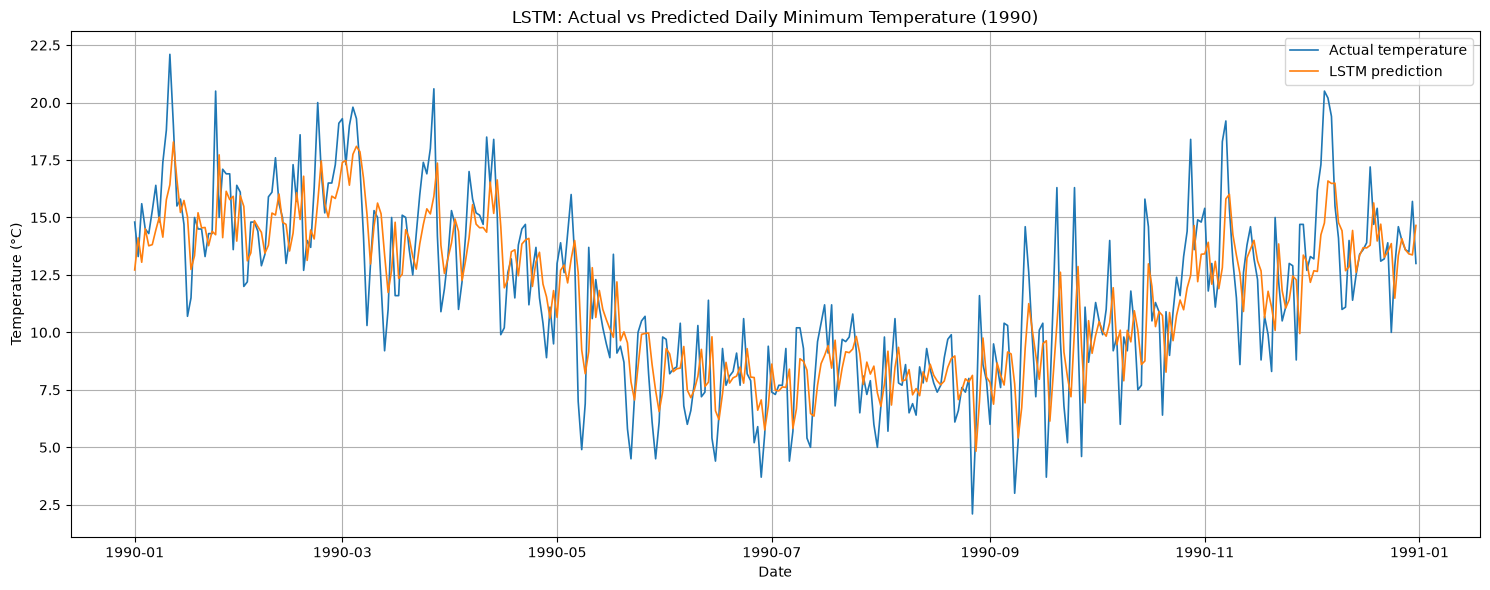

In [44]:

# Compare actual and predicted temperatures over 1990
plt.figure(figsize=(15, 6))

plt.plot(
    lstm_test.index,
    lstm_actual,
    label="Actual temperature",
    linewidth=1.2
)

plt.plot(
    lstm_test.index,
    lstm_predictions,
    label="LSTM prediction",
    linewidth=1.2
)

plt.title("LSTM: Actual vs Predicted Daily Minimum Temperature (1990)")
plt.xlabel("Date")
plt.ylabel("Temperature (°C)")
plt.legend()
plt.tight_layout()
plt.show()


In [45]:

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, GRU, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping

# Reproducibility
tf.keras.utils.set_random_seed(42)

# Build the GRU model
gru_model = Sequential([
    Input(shape=(sequence_length, 1)),
    GRU(64),
    Dropout(0.2),
    Dense(32, activation="relu"),
    Dense(1)
])

# Compile the model
gru_model.compile(
    optimizer="adam",
    loss="mse"
)

# Stop training if validation loss stops improving
gru_early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=10,
    restore_best_weights=True
)

# Train the model
gru_history = gru_model.fit(
    X_train,
    y_train,
    epochs=100,
    batch_size=32,
    validation_split=0.1,
    shuffle=False,
    callbacks=[gru_early_stopping],
    verbose=1
)


Epoch 1/100
92/92 ━━━━━━━━━━━━━━━━━━━━ 3s 12ms/step - loss: 0.0237 - val_loss: 0.0087
Epoch 2/100
92/92 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - loss: 0.0121 - val_loss: 0.0078
Epoch 3/100
92/92 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - loss: 0.0110 - val_loss: 0.0076
Epoch 4/100
92/92 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - loss: 0.0106 - val_loss: 0.0072
Epoch 5/100
92/92 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - loss: 0.0101 - val_loss: 0.0071
Epoch 6/100
92/92 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - loss: 0.0099 - val_loss: 0.0069
Epoch 7/100
92/92 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - loss: 0.0098 - val_loss: 0.0069
Epoch 8/100
92/92 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - loss: 0.0096 - val_loss: 0.0069
Epoch 9/100
92/92 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - loss: 0.0097 - val_loss: 0.0069
Epoch 10/100
92/92 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - loss: 0.0095 - val_loss: 0.0068
Epoch 11/100
92/92 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - loss: 0.0094 - val_loss: 0.0069
Epoch 12/100
92/92 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - loss: 0.

In [46]:

# Generate GRU predictions
gru_predictions_scaled = gru_model.predict(X_test, verbose=0)

# Convert predictions and actual values back to Celsius
gru_predictions = scaler.inverse_transform(
    gru_predictions_scaled
).flatten()

gru_actual = scaler.inverse_transform(
    y_test.reshape(-1, 1)
).flatten()

# Calculate GRU test metrics
gru_mae = mean_absolute_error(gru_actual, gru_predictions)
gru_rmse = np.sqrt(
    mean_squared_error(gru_actual, gru_predictions)
)

# Compare all models using the same rolling one-day-ahead test setup
comparison = pd.DataFrame({
    "Model": ["LSTM", "GRU", "Persistence baseline"],
    "MAE (°C)": [lstm_mae, gru_mae, baseline_mae],
    "RMSE (°C)": [lstm_rmse, gru_rmse, baseline_rmse]
})

print(comparison.round(3).to_string(index=False))


               Model  MAE (°C)  RMSE (°C)
                LSTM     1.746      2.271
                 GRU     1.720      2.233
Persistence baseline     2.025      2.582


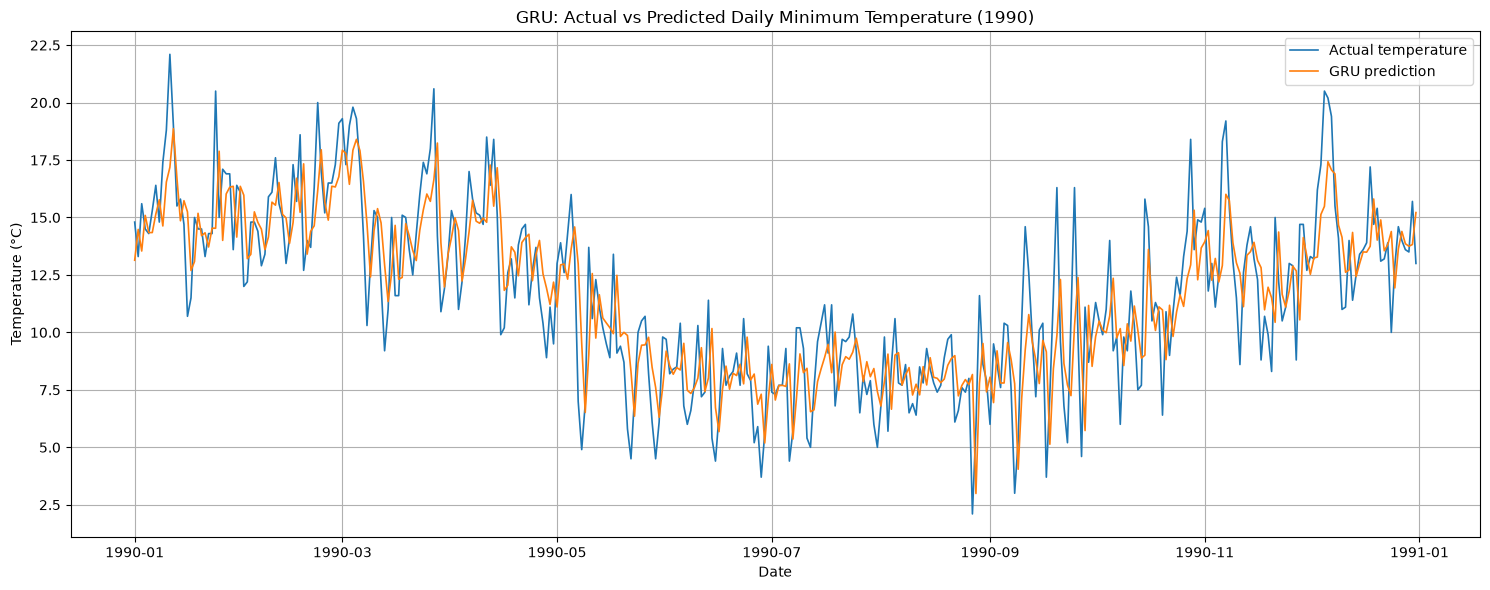

In [47]:

plt.figure(figsize=(15, 6))

plt.plot(
    lstm_test.index,
    gru_actual,
    label="Actual temperature",
    linewidth=1.2
)

plt.plot(
    lstm_test.index,
    gru_predictions,
    label="GRU prediction",
    linewidth=1.2
)

plt.title("GRU: Actual vs Predicted Daily Minimum Temperature (1990)")
plt.xlabel("Date")
plt.ylabel("Temperature (°C)")
plt.legend()
plt.tight_layout()
plt.show()


In [48]:

model_comparison = pd.DataFrame([
    {
        "Model": "Annual seasonal naive",
        "Forecast setup": "Full-year ahead",
        "MAE (°C)": 2.867,
        "RMSE (°C)": 3.651
    },
    {
        "Model": "Fourier + ARIMA(2,0,1)",
        "Forecast setup": "Full-year ahead",
        "MAE (°C)": 1.950,
        "RMSE (°C)": 2.540
    },
    {
        "Model": "Persistence baseline",
        "Forecast setup": "Rolling one-day ahead",
        "MAE (°C)": baseline_mae,
        "RMSE (°C)": baseline_rmse
    },
    {
        "Model": "LSTM",
        "Forecast setup": "Rolling one-day ahead",
        "MAE (°C)": lstm_mae,
        "RMSE (°C)": lstm_rmse
    },
    {
        "Model": "GRU",
        "Forecast setup": "Rolling one-day ahead",
        "MAE (°C)": gru_mae,
        "RMSE (°C)": gru_rmse
    }
])

print(model_comparison.round(3).to_string(index=False))


                 Model        Forecast setup  MAE (°C)  RMSE (°C)
 Annual seasonal naive       Full-year ahead     2.867      3.651
Fourier + ARIMA(2,0,1)       Full-year ahead     1.950      2.540
  Persistence baseline Rolling one-day ahead     2.025      2.582
                  LSTM Rolling one-day ahead     1.746      2.271
                   GRU Rolling one-day ahead     1.720      2.233


In [50]:

from statsmodels.tsa.statespace.sarimax import SARIMAX
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np
import pandas as pd

# Training data: 1981–1989
rolling_train = train.copy()
rolling_train.name = "temperature"
rolling_train.index = pd.date_range(
    start=rolling_train.index[0],
    periods=len(rolling_train),
    freq="D"
)

# Test data: 1990
rolling_test = test.copy()
rolling_test.index = pd.date_range(
    start=rolling_train.index[-1] + pd.Timedelta(days=1),
    periods=len(rolling_test),
    freq="D"
)

rolling_train_exog = make_fourier_features(
    rolling_train.index, period=365.25, K=2
)

rolling_result = SARIMAX(
    rolling_train,
    exog=rolling_train_exog,
    order=(2, 0, 1),
    seasonal_order=(0, 0, 0, 0),
    enforce_stationarity=True,
    enforce_invertibility=True
).fit(disp=False, maxiter=500)

rolling_predictions = []

for i in range(len(rolling_test)):
    next_date = rolling_test.index[i]

    next_exog = make_fourier_features(
        pd.DatetimeIndex([next_date]),
        period=365.25,
        K=2
    )

    prediction = rolling_result.forecast(
        steps=1,
        exog=next_exog
    ).iloc[0]

    rolling_predictions.append(float(prediction))

    # Match the name of the original training Series
    new_observation = pd.Series(
        [rolling_test.iloc[i]],
        index=[next_date],
        name="temperature"
    )

    rolling_result = rolling_result.append(
        new_observation,
        exog=next_exog,
        refit=False
    )

fourier_arima_rolling_forecast = pd.Series(
    rolling_predictions,
    index=rolling_test.index,
    name="Fourier + ARIMA rolling forecast"
)

fourier_arima_rolling_mae = mean_absolute_error(
    rolling_test.to_numpy(),
    fourier_arima_rolling_forecast.to_numpy()
)

fourier_arima_rolling_rmse = np.sqrt(
    mean_squared_error(
        rolling_test.to_numpy(),
        fourier_arima_rolling_forecast.to_numpy()
    )
)

print("Fourier + ARIMA rolling one-day-ahead results")
print(f"MAE:  {fourier_arima_rolling_mae:.3f} °C")
print(f"RMSE: {fourier_arima_rolling_rmse:.3f} °C")


d:\Capstone project 2\myenv\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:679: EstimationWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.
  start_params = self.start_params
d:\Capstone project 2\myenv\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:679: EstimationWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  start_params = self.start_params


Fourier + ARIMA rolling one-day-ahead results
MAE:  1.730 °C
RMSE: 2.217 °C


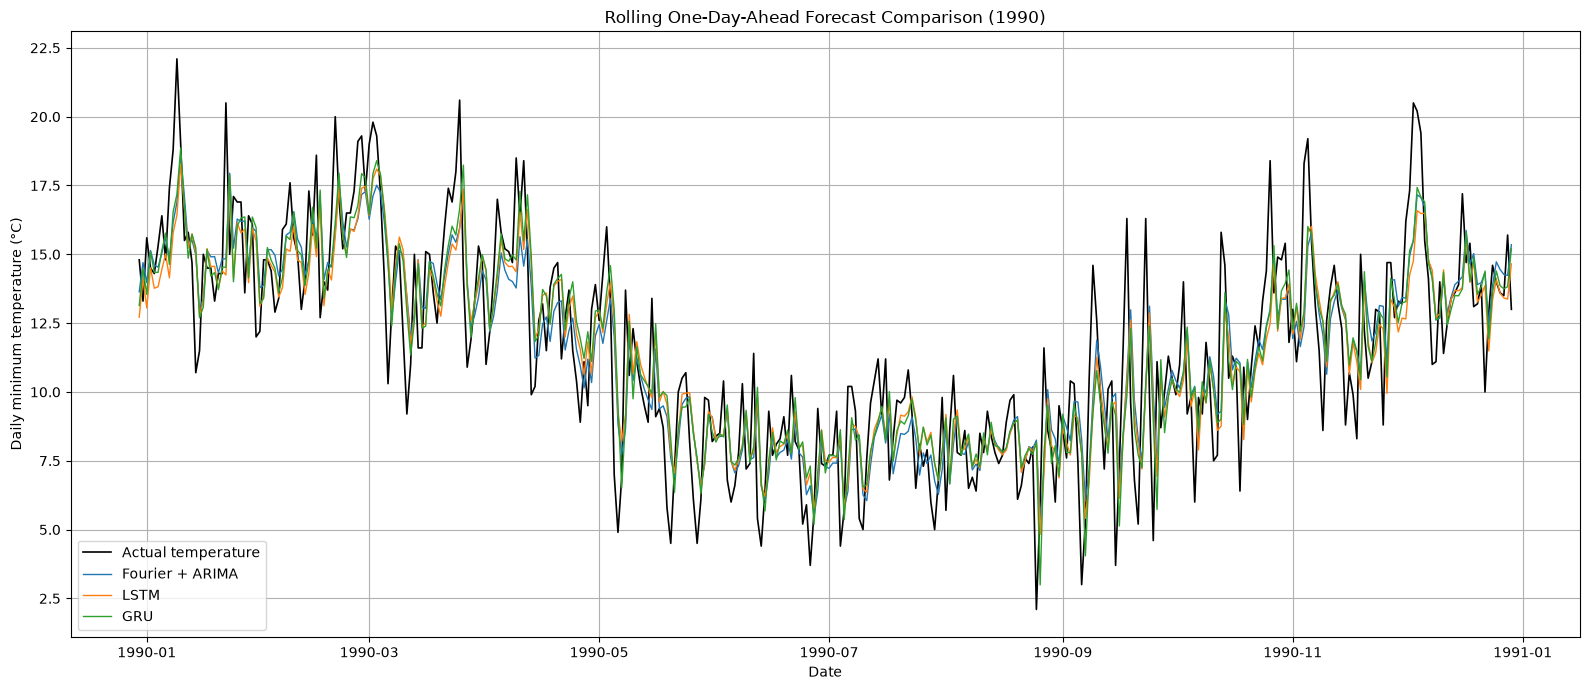

In [51]:

plt.figure(figsize=(16, 7))

plt.plot(
    rolling_test.index,
    rolling_test.to_numpy(),
    label="Actual temperature",
    color="black",
    linewidth=1.2
)

plt.plot(
    rolling_test.index,
    fourier_arima_rolling_forecast.to_numpy(),
    label="Fourier + ARIMA",
    linewidth=1
)

plt.plot(
    rolling_test.index,
    lstm_predictions,
    label="LSTM",
    linewidth=1
)

plt.plot(
    rolling_test.index,
    gru_predictions,
    label="GRU",
    linewidth=1
)

plt.title("Rolling One-Day-Ahead Forecast Comparison (1990)")
plt.xlabel("Date")
plt.ylabel("Daily minimum temperature (°C)")
plt.legend()
plt.tight_layout()
plt.show()


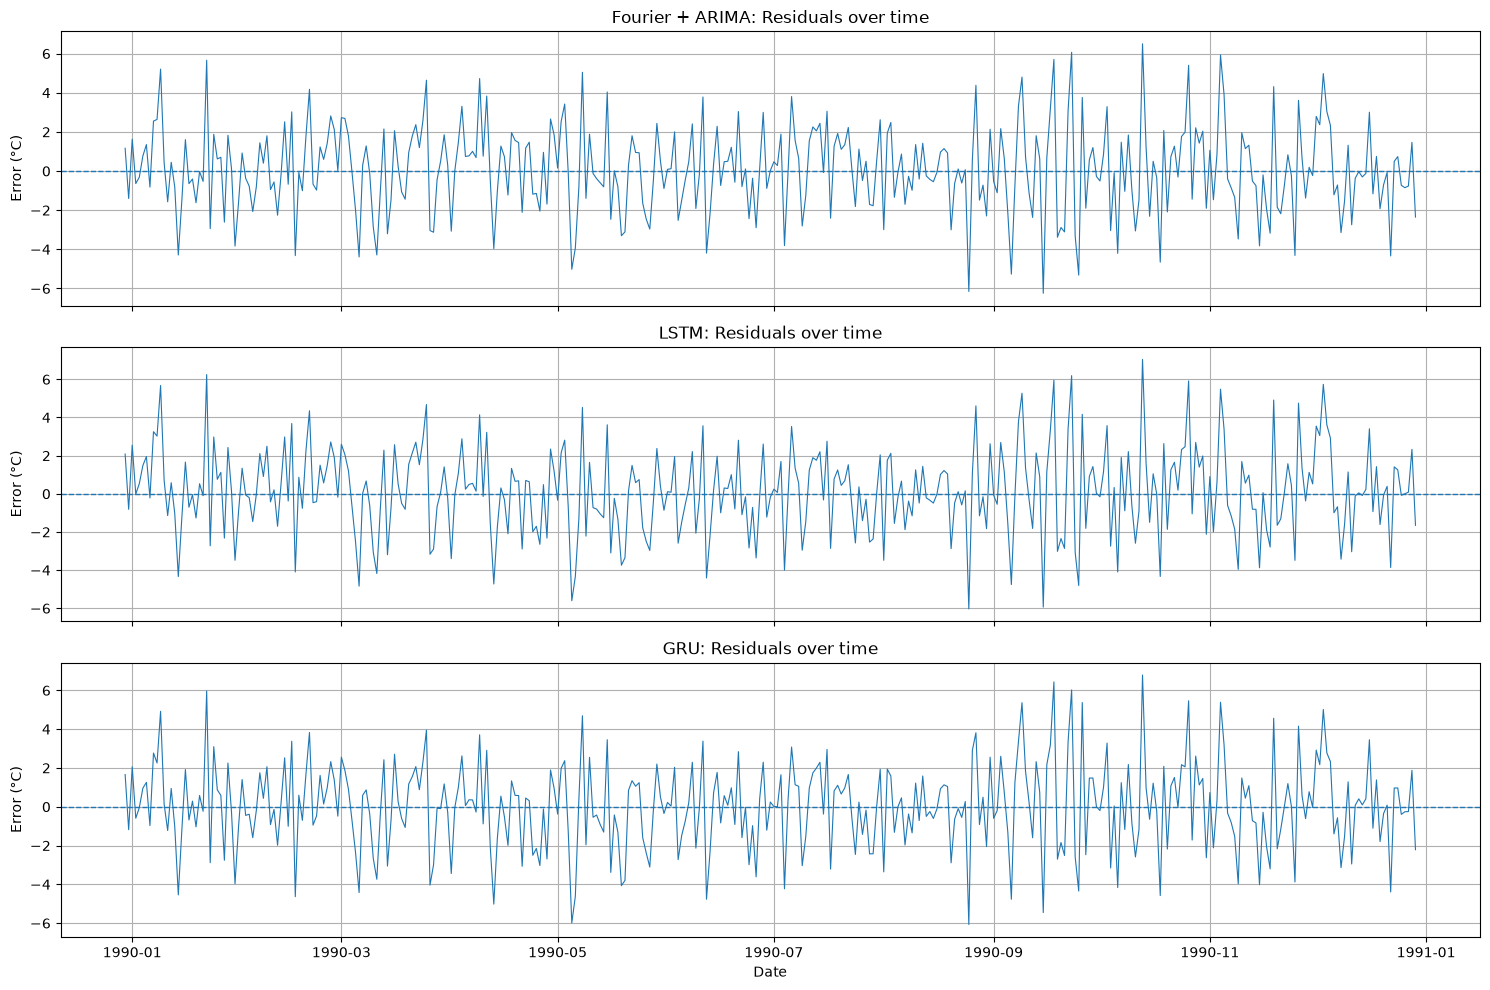

In [52]:

# Calculate residuals: actual temperature - predicted temperature

actual = rolling_test.to_numpy()

residuals = pd.DataFrame({
    "Fourier + ARIMA": actual - fourier_arima_rolling_forecast.to_numpy(),
    "LSTM": actual - lstm_predictions,
    "GRU": actual - gru_predictions
}, index=rolling_test.index)

# Plot residuals over time
fig, axes = plt.subplots(3, 1, figsize=(15, 10), sharex=True)

for ax, model_name in zip(axes, residuals.columns):
    ax.plot(residuals.index, residuals[model_name], linewidth=0.8)
    ax.axhline(0, linestyle="--", linewidth=1)
    ax.set_title(f"{model_name}: Residuals over time")
    ax.set_ylabel("Error (°C)")

axes[-1].set_xlabel("Date")
plt.tight_layout()
plt.show()


In [53]:

from statsmodels.stats.diagnostic import acorr_ljungbox

# Summarize residual errors
residual_summary = pd.DataFrame({
    "Mean error (°C)": residuals.mean(),
    "Residual std (°C)": residuals.std(),
    "Largest absolute error (°C)": residuals.abs().max()
})

print("Residual summary:")
print(residual_summary.round(3))

# Ljung-Box test for remaining autocorrelation
for model_name in residuals.columns:
    lb_result = acorr_ljungbox(
        residuals[model_name],
        lags=[7, 14, 30],
        return_df=True
    )

    print(f"\nLjung-Box test: {model_name}")
    print(lb_result.round(4))


Residual summary:
                 Mean error (°C)  Residual std (°C)  \
Fourier + ARIMA            0.088              2.219   
LSTM                       0.135              2.270   
GRU                        0.030              2.236   

                 Largest absolute error (°C)  
Fourier + ARIMA                        6.501  
LSTM                                   7.043  
GRU                                    6.791  

Ljung-Box test: Fourier + ARIMA
    lb_stat  lb_pvalue
7   14.0671     0.0500
14  18.6331     0.1794
30  46.2488     0.0294

Ljung-Box test: LSTM
    lb_stat  lb_pvalue
7    6.3841     0.4957
14  10.8287     0.6994
30  35.0619     0.2404

Ljung-Box test: GRU
    lb_stat  lb_pvalue
7    4.9858     0.6617
14   8.8620     0.8398
30  35.2839     0.2325


In [54]:

# Final validation: test-set alignment and prediction lengths

print("TEST SET VALIDATION")
print("-" * 45)

print("Number of test observations:", len(rolling_test))
print("Test period:", rolling_test.index.min(), "to", rolling_test.index.max())

# Check forecast lengths
forecast_lengths = {
    "Fourier + ARIMA": len(fourier_arima_rolling_forecast),
    "LSTM": len(lstm_predictions),
    "GRU": len(gru_predictions),
    "Persistence baseline": len(persistence_forecast)
}

print("\nForecast lengths:")
for model_name, length in forecast_lengths.items():
    print(f"{model_name}: {length}")

# Check that all forecasts use the same actual observations
assert len(rolling_test) == 365, "Expected 365 test observations."
assert all(length == len(rolling_test) for length in forecast_lengths.values()), (
    "A forecast length does not match the test set."
)

assert np.allclose(
    rolling_test.to_numpy(),
    lstm_test.to_numpy()
), "The rolling test series and LSTM test series differ."

assert np.allclose(
    rolling_test.to_numpy(),
    lstm_actual
), "The actual values used for LSTM evaluation differ."

assert np.allclose(
    rolling_test.to_numpy(),
    gru_actual
), "The actual values used for GRU evaluation differ."

print("\nAll length and actual-value checks passed.")


TEST SET VALIDATION
---------------------------------------------
Number of test observations: 365
Test period: 1989-12-30 00:00:00 to 1990-12-29 00:00:00

Forecast lengths:
Fourier + ARIMA: 365
LSTM: 365
GRU: 365
Persistence baseline: 365

All length and actual-value checks passed.


In [55]:

print("Original train dates:")
print("Start:", train.index.min())
print("End:  ", train.index.max())

print("\nOriginal test dates:")
print("Start:", test.index.min())
print("End:  ", test.index.max())

print("\nLSTM train dates:")
print("Start:", lstm_train.index.min())
print("End:  ", lstm_train.index.max())

print("\nLSTM test dates:")
print("Start:", lstm_test.index.min())
print("End:  ", lstm_test.index.max())


Original train dates:
Start: 1981-01-01 00:00:00
End:   1989-12-31 00:00:00

Original test dates:
Start: 1990-01-01 00:00:00
End:   1990-12-31 00:00:00

LSTM train dates:
Start: 1981-01-01 00:00:00
End:   1989-12-31 00:00:00

LSTM test dates:
Start: 1990-01-01 00:00:00
End:   1990-12-31 00:00:00


In [56]:

# Use the original calendar dates for the 1990 test year
correct_test_index = test.index

# Align rolling test observations to the correct dates
rolling_test = pd.Series(
    test.to_numpy(),
    index=correct_test_index,
    name="temperature"
)

# Align all existing rolling forecasts to the same dates
fourier_arima_rolling_forecast.index = correct_test_index

# Recreate residuals using correctly aligned dates
residuals = pd.DataFrame({
    "Fourier + ARIMA": (
        rolling_test.to_numpy()
        - fourier_arima_rolling_forecast.to_numpy()
    ),
    "LSTM": lstm_actual - rolling_test.to_numpy(),
    "GRU": gru_actual - rolling_test.to_numpy()
}, index=correct_test_index)

print("Corrected test period:")
print(rolling_test.index.min(), "to", rolling_test.index.max())

print("\nForecast lengths:")
print("Fourier + ARIMA:", len(fourier_arima_rolling_forecast))
print("LSTM:", len(lstm_predictions))
print("GRU:", len(gru_predictions))

assert rolling_test.index.equals(test.index)
assert len(rolling_test) == 365
assert len(fourier_arima_rolling_forecast) == 365

print("\nDate alignment corrected.")


Corrected test period:
1990-01-01 00:00:00 to 1990-12-31 00:00:00

Forecast lengths:
Fourier + ARIMA: 365
LSTM: 365
GRU: 365

Date alignment corrected.


In [57]:
print("Actual test period:", test.index.min(), "to", test.index.max())
print("Fourier + ARIMA forecast period:",
      fourier_arima_rolling_forecast.index.min(), "to",
      fourier_arima_rolling_forecast.index.max())

print("\nFirst 5 actual dates:")
print(test.index[:5])

print("\nFirst 5 forecast dates:")
print(fourier_arima_rolling_forecast.index[:5])

print("\nForecast lengths:")
print("Actual:", len(test))
print("Fourier + ARIMA:", len(fourier_arima_rolling_forecast))
print("LSTM:", len(lstm_predictions))
print("GRU:", len(gru_predictions))

Actual test period: 1990-01-01 00:00:00 to 1990-12-31 00:00:00
Fourier + ARIMA forecast period: 1990-01-01 00:00:00 to 1990-12-31 00:00:00

First 5 actual dates:
DatetimeIndex(['1990-01-01', '1990-01-02', '1990-01-03', '1990-01-04',
               '1990-01-05'],
              dtype='datetime64[us]', name='date', freq=None)

First 5 forecast dates:
DatetimeIndex(['1990-01-01', '1990-01-02', '1990-01-03', '1990-01-04',
               '1990-01-05'],
              dtype='datetime64[us]', name='date', freq=None)

Forecast lengths:
Actual: 365
Fourier + ARIMA: 365
LSTM: 365
GRU: 365


In [58]:
from statsmodels.tsa.statespace.sarimax import SARIMAX
from sklearn.metrics import mean_absolute_error, mean_squared_error

# Preserve the actual calendar dates for Fourier features
rolling_train_values = train.to_numpy()
rolling_test_values = test.to_numpy()

train_dates = train.index
test_dates = test.index

# Use consecutive integer indexes for the ARIMA time steps
y_train_rolling = pd.Series(
    rolling_train_values,
    index=pd.RangeIndex(len(rolling_train_values)),
    name="temperature"
)

train_fourier = make_fourier_features(
    train_dates, period=365.25, K=2
)
train_fourier.index = y_train_rolling.index

# Fit the model using correctly dated Fourier features
rolling_result = SARIMAX(
    y_train_rolling,
    exog=train_fourier,
    order=(2, 0, 1),
    seasonal_order=(0, 0, 0, 0),
    enforce_stationarity=True,
    enforce_invertibility=True
).fit(disp=False, maxiter=500)

corrected_predictions = []

for i, date in enumerate(test_dates):
    next_index = len(rolling_train_values) + i

    # Fourier features use the actual calendar date
    next_fourier = make_fourier_features(
        pd.DatetimeIndex([date]),
        period=365.25,
        K=2
    )
    next_fourier.index = pd.RangeIndex(
        next_index, next_index + 1
    )

    # Predict one day ahead
    prediction = rolling_result.forecast(
        steps=1, exog=next_fourier
    ).iloc[0]

    corrected_predictions.append(float(prediction))

    # Update with the actual observation; do not refit parameters
    actual_observation = pd.Series(
        [rolling_test_values[i]],
        index=pd.RangeIndex(next_index, next_index + 1),
        name="temperature"
    )

    rolling_result = rolling_result.append(
        actual_observation,
        exog=next_fourier,
        refit=False
    )

# Restore actual calendar dates on the final forecast series
fourier_arima_rolling_forecast = pd.Series(
    corrected_predictions,
    index=test_dates,
    name="Fourier + ARIMA rolling forecast"
)

# Calculate corrected metrics
fourier_arima_rolling_mae = mean_absolute_error(
    rolling_test_values, corrected_predictions
)
fourier_arima_rolling_rmse = np.sqrt(
    mean_squared_error(rolling_test_values, corrected_predictions)
)

print("Corrected Fourier + ARIMA rolling MAE:",
      round(fourier_arima_rolling_mae, 3))
print("Corrected Fourier + ARIMA rolling RMSE:",
      round(fourier_arima_rolling_rmse, 3))
print("Forecast length:", len(fourier_arima_rolling_forecast))
print("Forecast dates:",
      fourier_arima_rolling_forecast.index.min(),
      "to",
      fourier_arima_rolling_forecast.index.max())

d:\Capstone project 2\myenv\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:679: EstimationWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.
  start_params = self.start_params
d:\Capstone project 2\myenv\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:679: EstimationWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  start_params = self.start_params


Corrected Fourier + ARIMA rolling MAE: 1.733
Corrected Fourier + ARIMA rolling RMSE: 2.218
Forecast length: 365
Forecast dates: 1990-01-01 00:00:00 to 1990-12-31 00:00:00


In [59]:
from sklearn.metrics import mean_absolute_error, mean_squared_error

# Actual temperatures for the 1990 test period
actual = test.to_numpy()

# Ensure all forecasts contain 365 predictions in the same chronological order
lstm_forecast = np.asarray(lstm_predictions).flatten()
gru_forecast = np.asarray(gru_predictions).flatten()
arima_forecast = fourier_arima_rolling_forecast.to_numpy()

# Create a common model-comparison table
comparison = pd.DataFrame({
    "Model": [
        "Fourier + ARIMA",
        "LSTM",
        "GRU"
    ],
    "MAE": [
        mean_absolute_error(actual, arima_forecast),
        mean_absolute_error(actual, lstm_forecast),
        mean_absolute_error(actual, gru_forecast)
    ],
    "RMSE": [
        np.sqrt(mean_squared_error(actual, arima_forecast)),
        np.sqrt(mean_squared_error(actual, lstm_forecast)),
        np.sqrt(mean_squared_error(actual, gru_forecast))
    ]
})

comparison = comparison.sort_values("MAE").reset_index(drop=True)

print("Model comparison — rolling one-day-ahead forecasts")
display(comparison.round(3))

Model comparison — rolling one-day-ahead forecasts


,Model,MAE,RMSE
0,GRU,1.720,2.233
1,Fourier + ARIMA,1.733,2.218
2,LSTM,1.746,2.271


In [60]:
from sklearn.metrics import r2_score

comparison = pd.DataFrame({
    "Model": [
        "Fourier + ARIMA",
        "LSTM",
        "GRU"
    ],
    "MAE": [
        mean_absolute_error(actual, arima_forecast),
        mean_absolute_error(actual, lstm_forecast),
        mean_absolute_error(actual, gru_forecast)
    ],
    "RMSE": [
        np.sqrt(mean_squared_error(actual, arima_forecast)),
        np.sqrt(mean_squared_error(actual, lstm_forecast)),
        np.sqrt(mean_squared_error(actual, gru_forecast))
    ],
    "R2": [
        r2_score(actual, arima_forecast),
        r2_score(actual, lstm_forecast),
        r2_score(actual, gru_forecast)
    ]
})

comparison = comparison.sort_values(
    "MAE"
).reset_index(drop=True)

display(comparison.round(4))

,Model,MAE,RMSE,R2
0,GRU,1.7195,2.2332,0.6646
1,Fourier + ARIMA,1.7326,2.2185,0.6690
2,LSTM,1.7456,2.2710,0.6532


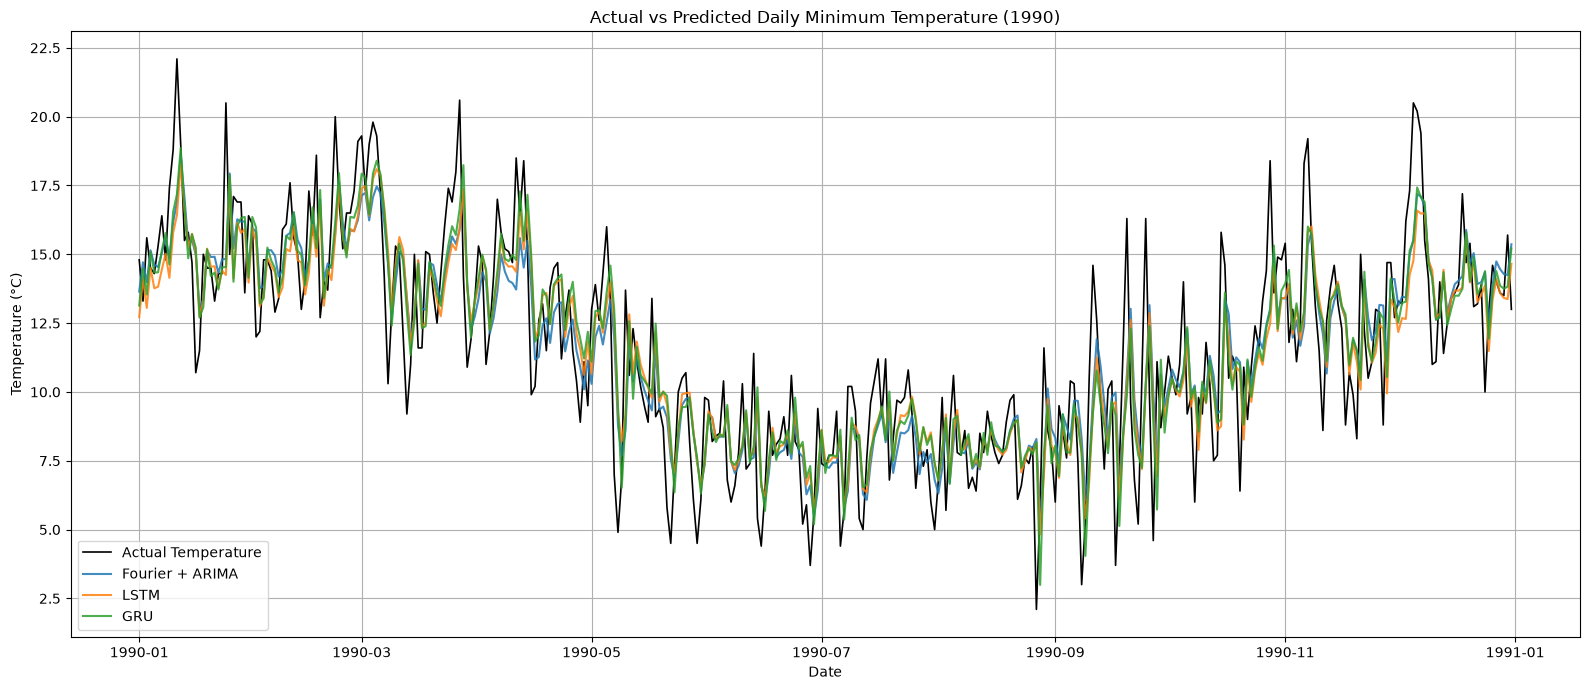

In [61]:
plt.figure(figsize=(16, 7))

plt.plot(
    test.index, actual,
    label="Actual Temperature",
    color="black", linewidth=1.2
)

plt.plot(
    test.index, arima_forecast,
    label="Fourier + ARIMA",
    alpha=0.85
)

plt.plot(
    test.index, lstm_forecast,
    label="LSTM",
    alpha=0.85
)

plt.plot(
    test.index, gru_forecast,
    label="GRU",
    alpha=0.85
)

plt.title("Actual vs Predicted Daily Minimum Temperature (1990)")
plt.xlabel("Date")
plt.ylabel("Temperature (°C)")
plt.legend()
plt.tight_layout()
plt.show()

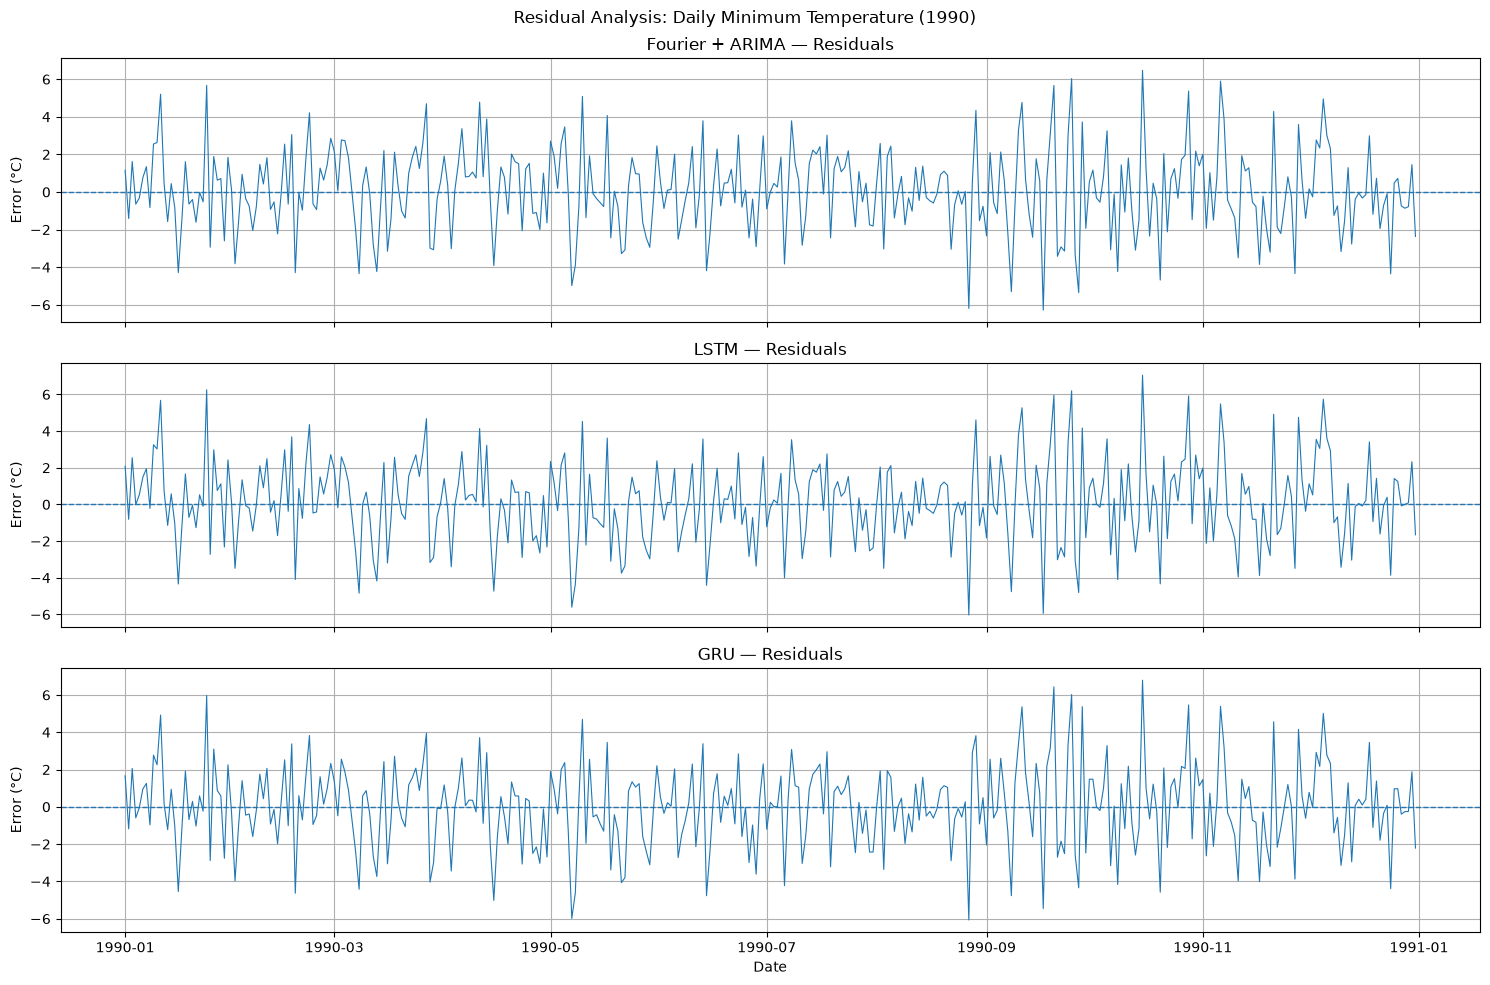

In [62]:
# Calculate residuals
residuals = pd.DataFrame(
    {
        "Fourier + ARIMA": actual - arima_forecast,
        "LSTM": actual - lstm_forecast,
        "GRU": actual - gru_forecast
    },
    index=test.index
)

# Plot residuals over time
fig, axes = plt.subplots(3, 1, figsize=(15, 10), sharex=True)

for ax, model in zip(axes, residuals.columns):
    ax.plot(residuals.index, residuals[model], linewidth=0.8)
    ax.axhline(0, linestyle="--", linewidth=1)
    ax.set_title(f"{model} — Residuals")
    ax.set_ylabel("Error (°C)")

axes[-1].set_xlabel("Date")
plt.suptitle("Residual Analysis: Daily Minimum Temperature (1990)")
plt.tight_layout()
plt.show()

In [64]:

# ============================================================
# CREATE AND SAVE THE BEST MODEL: FOURIER + ARIMA(2, 0, 1)
# Jupyter Notebook compatible
# ============================================================

from pathlib import Path
import json
import pickle
import warnings

import numpy as np
import pandas as pd
import statsmodels

from statsmodels.tsa.statespace.sarimax import SARIMAX


# ------------------------------------------------------------
# 1. File paths (Jupyter-compatible: no __file__)
# ------------------------------------------------------------

BASE_DIR = Path.cwd()

DATA_FILE = BASE_DIR / "CP2_data_ts.csv"
MODEL_FILE = BASE_DIR / "fourier_arima_model.pkl"
METADATA_FILE = BASE_DIR / "model_metadata.json"

print("Working directory:", BASE_DIR)
print("Dataset exists:", DATA_FILE.exists())

if not DATA_FILE.exists():
    raise FileNotFoundError(
        f"Cannot find {DATA_FILE.name} in {BASE_DIR}.\n"
        "Set BASE_DIR to the folder containing your CSV file."
    )


# ------------------------------------------------------------
# 2. Load and clean the dataset
# ------------------------------------------------------------

raw = pd.read_csv(DATA_FILE)

if raw.shape[1] < 2:
    raise ValueError(
        "The CSV must contain date and temperature columns."
    )

df = raw.iloc[:, :2].copy()
df.columns = ["date_original", "temperature_original"]

# Parse dates using day-month-year format.
df["date"] = pd.to_datetime(
    df["date_original"],
    format="%d-%m-%Y",
    errors="coerce"
)

# Fallback if the date format differs.
if df["date"].isna().any():
    df["date"] = pd.to_datetime(
        df["date_original"],
        errors="coerce",
        dayfirst=True
    )

# Convert invalid temperature strings such as '?0.2' to NaN.
df["temperature"] = pd.to_numeric(
    df["temperature_original"].astype(str).str.strip(),
    errors="coerce"
)

# Sort and remove invalid dates and duplicate dates.
df = df.dropna(subset=["date"])
df = df.sort_values("date")
df = df.drop_duplicates(subset=["date"], keep="first")
df = df.set_index("date")

if df["temperature"].notna().sum() < 100:
    raise ValueError(
        "Too few valid temperature observations were found."
    )

# Interpolate missing temperatures by time.
df["temperature"] = df["temperature"].interpolate(
    method="time"
)

df["temperature"] = df["temperature"].ffill().bfill()

if df["temperature"].isna().any():
    raise ValueError(
        "Missing temperatures remain after cleaning."
    )

print("\nDataset cleaned successfully.")
print("Observations:", len(df))
print("Start date:", df.index.min())
print("End date:", df.index.max())


# ------------------------------------------------------------
# 3. Define Fourier feature function
# ------------------------------------------------------------

def make_fourier_features(
    dates,
    period=365.25,
    harmonics=2
):
    """
    Generate annual Fourier features from actual calendar dates.
    Feature order: sin_1, cos_1, sin_2, cos_2.
    """

    dates = pd.DatetimeIndex(dates)

    elapsed_days = (
        dates - pd.Timestamp("1981-01-01")
    ).days.to_numpy()

    features = pd.DataFrame(index=dates)

    for k in range(1, harmonics + 1):
        features[f"sin_{k}"] = np.sin(
            2 * np.pi * k * elapsed_days / period
        )

        features[f"cos_{k}"] = np.cos(
            2 * np.pi * k * elapsed_days / period
        )

    return features


# ------------------------------------------------------------
# 4. Prepare model inputs
# ------------------------------------------------------------

dates = pd.DatetimeIndex(df.index)

temperature_values = df["temperature"].to_numpy(
    dtype=float
)

# The model uses an integer index for consecutive observations.
y = pd.Series(
    temperature_values,
    index=pd.RangeIndex(len(temperature_values)),
    name="temperature"
)

# Create Fourier features using actual calendar dates.
exog = make_fourier_features(
    dates,
    period=365.25,
    harmonics=2
)

# Preserve exactly the feature order used by the app.
exog = exog[
    ["sin_1", "cos_1", "sin_2", "cos_2"]
]

# Align Fourier features to the model's integer index.
exog.index = y.index

print("\nModel input shapes:")
print("Target:", y.shape)
print("Fourier features:", exog.shape)


# ------------------------------------------------------------
# 5. Fit Fourier + ARIMA(2, 0, 1)
# ------------------------------------------------------------

print("\nTraining Fourier + ARIMA(2, 0, 1)...")

with warnings.catch_warnings():
    warnings.simplefilter("default")

    model = SARIMAX(
        y,
        exog=exog,
        order=(2, 0, 1),
        seasonal_order=(0, 0, 0, 0),
        enforce_stationarity=True,
        enforce_invertibility=True
    )

    fitted_model = model.fit(
        disp=False,
        maxiter=500
    )

converged = bool(
    fitted_model.mle_retvals.get("converged", False)
)

print("\nTraining results:")
print("Converged:", converged)
print("AIC:", round(float(fitted_model.aic), 3))

if not converged:
    raise RuntimeError(
        "The model did not converge. "
        "No model file has been saved."
    )


# ------------------------------------------------------------
# 6. Save the fitted model
# ------------------------------------------------------------

with open(MODEL_FILE, "wb") as file:
    pickle.dump(
        fitted_model,
        file,
        protocol=pickle.HIGHEST_PROTOCOL
    )

print("\nSaved fitted model:")
print(MODEL_FILE)
print(
    "Model size:",
    round(MODEL_FILE.stat().st_size / (1024 ** 2), 2),
    "MB"
)


# ------------------------------------------------------------
# 7. Save model metadata
# ------------------------------------------------------------

metadata = {
    "model_name": "Fourier + ARIMA",
    "arima_order": [2, 0, 1],
    "seasonal_order": [0, 0, 0, 0],
    "fourier_period_days": 365.25,
    "fourier_harmonics": 2,
    "fourier_feature_order": [
        "sin_1",
        "cos_1",
        "sin_2",
        "cos_2"
    ],
    "fourier_epoch": "1981-01-01",
    "training_observations": int(len(df)),
    "training_start": str(df.index.min().date()),
    "training_end": str(df.index.max().date()),
    "converged": converged,
    "aic": float(fitted_model.aic),
    "statsmodels_version": statsmodels.__version__,
    "pandas_version": pd.__version__
}

METADATA_FILE.write_text(
    json.dumps(metadata, indent=4),
    encoding="utf-8"
)

print("\nSaved metadata:")
print(METADATA_FILE)


# ------------------------------------------------------------
# 8. Verify that the saved model can be loaded
# ------------------------------------------------------------

with open(MODEL_FILE, "rb") as file:
    loaded_model = pickle.load(file)

print("\nVerification:")
print("Model file exists:", MODEL_FILE.exists())
print("Metadata file exists:", METADATA_FILE.exists())
print(
    "Loaded model order:",
    loaded_model.model.order
)
print(
    "Loaded model observations:",
    loaded_model.nobs
)

print("\nSUCCESS: Model trained, saved and reloaded.")


Working directory: d:\Capstone project 2
Dataset exists: True

Dataset cleaned successfully.
Observations: 3650
Start date: 1981-01-01 00:00:00
End date: 1990-12-31 00:00:00

Model input shapes:
Target: (3650,)
Fourier features: (3650, 4)

Training Fourier + ARIMA(2, 0, 1)...


d:\Capstone project 2\myenv\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:679: EstimationWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.
  start_params = self.start_params
d:\Capstone project 2\myenv\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:679: EstimationWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  start_params = self.start_params



Training results:
Converged: True
AIC: 16667.345

Saved fitted model:
d:\Capstone project 2\fourier_arima_model.pkl
Model size: 5.34 MB

Saved metadata:
d:\Capstone project 2\model_metadata.json

Verification:
Model file exists: True
Metadata file exists: True
Loaded model order: (2, 0, 1)
Loaded model observations: 3650

SUCCESS: Model trained, saved and reloaded.
